# Airbnb Cape Town Capstone

**Student:** Precious  
**Dataset:** Inside Airbnb, Cape Town listings snapshot (23 Sep 2026), CC BY 4.0  
Source: [Inside Airbnb - Get the Data](http://insideairbnb.com/get-the-data/)

This notebook covers two tasks on the same cleaned dataset:
- **Task C (classification, deployed in Streamlit app):** predict whether a host is a Superhost (`host_is_superhost`).
- **Task R (regression, notebook only):** predict listing price (`price`).

I keep the cleaning, EDA, and split logic shared where it makes sense, but I handle targets, leakage checks, metrics, and models separately for each task. Every important result is followed by a short written finding in my own words.

## A. Environment and repository (Checklist A)

**A1. Environment check**  
I use a local `venv` for this project. After activating it, I install dependencies from `requirements.txt` and run the import test below. I also record versions with `pip list` when finalizing requirements.

**A2. Git**  
I initialize Git in the project root, commit regularly, and make sure `venv/`, raw data, and generated artifacts are ignored (see `.gitignore`).

**A3. Folder layout**  
I keep the brief layout: `app.py`, `notebooks/`, `models/`, `reports/figures/`, `data/raw/`, `data/processed/`. Raw data stays untouched; cleaned outputs are written by code to `data/processed/`.

**A4. Requirements**  
`requirements.txt` is hand-written and pinned to the versions I actually use. I verify with `pip list` before submission.

In [41]:
from sklearn.base import clone
# A1 - imports and environment sanity check
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    GroupShuffleSplit, GroupKFold, cross_validate, cross_val_predict,
    RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    mean_squared_error, mean_absolute_error, silhouette_score
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# XGBoost is required by the todo (H4b). Install with: pip install xgboost
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except Exception as e:
    XGBOOST_AVAILABLE = False
    print('XGBoost not available:', e)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Everything works')
print('pandas', pd.__version__)
print('numpy', np.__version__)
import sklearn
print('sklearn', sklearn.__version__)
print('xgboost available:', XGBOOST_AVAILABLE)


Everything works
pandas 2.3.3
numpy 2.0.2
sklearn 1.6.1
xgboost available: True


In [42]:
# A3 - project paths (notebook lives in notebooks/)
PROJECT_DIR = Path('..').resolve()
DATA_DIR = PROJECT_DIR / 'data' / 'raw'
PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'
MODELS_DIR = PROJECT_DIR / 'models'
FIG_DIR = PROJECT_DIR / 'reports' / 'figures'

for p in [PROCESSED_DIR, MODELS_DIR, FIG_DIR]:
    p.mkdir(parents=True, exist_ok=True)

LISTINGS_PATH = DATA_DIR / 'listings.csv.gz'
NEIGH_PATH = DATA_DIR / 'neighbourhoods.csv'

print('Project:', PROJECT_DIR)
print('Listings exists:', LISTINGS_PATH.exists(), '-', LISTINGS_PATH)
print('Neighbourhoods exists:', NEIGH_PATH.exists(), '-', NEIGH_PATH)
print('Processed dir:', PROCESSED_DIR)
print('Models dir:', MODELS_DIR)


Project: C:\Users\Chibi\Pictures\Workspace\CAMLDS\Final\Final Capstone\airbnb-cape-town
Listings exists: True - C:\Users\Chibi\Pictures\Workspace\CAMLDS\Final\Final Capstone\airbnb-cape-town\data\raw\listings.csv.gz
Neighbourhoods exists: True - C:\Users\Chibi\Pictures\Workspace\CAMLDS\Final\Final Capstone\airbnb-cape-town\data\raw\neighbourhoods.csv
Processed dir: C:\Users\Chibi\Pictures\Workspace\CAMLDS\Final\Final Capstone\airbnb-cape-town\data\processed
Models dir: C:\Users\Chibi\Pictures\Workspace\CAMLDS\Final\Final Capstone\airbnb-cape-town\models


## B. Problem framing (Checklist B)

### B1. Business questions in my own words

**Task C - Superhost classification (deployed):**  
*Who uses it?* An Airbnb support or host-success team in Cape Town.  
*What decision does it support?* The model estimates whether a listing's host profile looks like a Superhost. The team can use this as a prioritization signal: for example, flag listings/hosts that look close to Superhost quality for coaching, or review cases where the model disagrees with expectations. It is not an official Airbnb label and should not replace Airbnb's own rules.

**Task R - Price regression (notebook only):**  
*Who uses it?* A host, listing manager, or analyst.  
*What decision does it support?* The model estimates a reasonable nightly price range based on listing characteristics. It can help a host sanity-check pricing, spot under/over-priced listings, or understand which features are associated with higher prices.

**Why classification vs regression?**  
Task C is classification because `host_is_superhost` is a category/label (`t` or `f`) - the answer is "which class?". Task R is regression because `price` is a numeric amount in rand - the answer is "how much?".

### B2. Target definitions
- `host_is_superhost`: map `t -> 1`, `f -> 0`. I print class counts after loading/cleaning. Rows with missing target are excluded from Task C modelling.
- `price`: parse currency strings like `$1,114.00` into numeric rand values. Missing/blank/invalid prices become `NaN` and are excluded from Task R modelling (I also report how many rows are affected). I inspect extreme prices before deciding whether to cap/remove them.

### B3. Metrics chosen before modelling
**Task C (Superhost, class imbalance expected):** I will report **F1, precision, recall, accuracy, and ROC-AUC**.  
Why not accuracy alone? Because if most hosts are not Superhosts, a model that predicts "not Superhost" for everyone can get decent accuracy while catching zero actual Superhosts. That would be useless for the support team. Recall matters when missing real Superhosts is costly; precision matters when false alarms waste team time. F1 balances precision and recall, and ROC-AUC summarizes ranking quality across thresholds.

**Task R (price):** I will report **RMSE and MAE** in rand.  
RMSE squares errors before averaging, so it punishes large mistakes more heavily. MAE is the average absolute error and is easier to read as "typical rand error". I use both because a model might have acceptable average error (MAE) but still make some very bad large-price mistakes (RMSE exposes this).

## C. Data loading and inspection (Checklist C)

I load the raw Inside Airbnb files from `data/raw/`, inspect structure and quality, fix obvious dtype issues, audit missing values, check duplicates/host repeats, and merge the neighbourhood lookup.

In [43]:
# C1 - Load raw listings
# compression='gzip' lets pandas read the .gz directly without manually unzipping.
df_raw = pd.read_csv(LISTINGS_PATH, compression='gzip', low_memory=False)
print('Shape:', df_raw.shape)
print('Rows:', df_raw.shape[0], 'Columns:', df_raw.shape[1])
df_raw.head(3)


Shape: (27760, 90)
Rows: 27760 Columns: 90


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,...,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,15007,https://www.airbnb.com/rooms/15007,20260923225056,2026-09-26,previous scrape,Blaauwberg House on the beach in Bloubergstrand,Welcome to our self-catering beach-front famil...,NaN,https://a0.muscache.com/pictures/3b654aa4-248e...,59072,https://www.airbnb.com/users/show/59072,1462507936690024262,https://www.airbnb.com/users/profile/146250793...,Dirk,NaN,16,9,15,8,"Cape Town, South Africa",Proud to live in the beautiful city of Cape To...,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/pictures/user/86c72...,NaN,9,NaN,...,NaN,t,0,0,0,0,2026-09-26,53,6,0,0,2,36,NaN,2013-12-15,2026-03-16,4.83,4.91,4.83,4.98,4.94,4.94,4.85,NaN,NaN,2,2,0,0,0.34
1,15077,https://www.airbnb.com/rooms/15077,20260923225056,2026-09-26,NaN,Superior Room | 100m to Sunset Beach | Cape Town,Our Superior Rooms (approx. 25 m²) offer a rel...,NaN,https://a0.muscache.com/pictures/4a8fceaa-655e...,59342,https://www.airbnb.com/users/show/59342,1462507943957675735,https://www.airbnb.com/users/profile/146250794...,Georg,NaN,16,9,15,8,Gibraltar,challenge us please! we love to perform!,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/pictures/user/User/...,NaN,7,NaN,...,NaN,t,7,21,42,278,2026-09-26,7,0,0,49,0,0,0.0,2013-01-06,2022-06-16,5.00,4.86,4.86,4.86,4.71,4.86,5.00,NaN,NaN,6,2,4,0,0.04
2,15199,https://www.airbnb.com/rooms/15199,20260923225056,2026-09-26,NaN,Self catering apartment,<b>The space</b><br />Amenities :<br />Welcome...,NaN,https://a0.muscache.com/pictures/142776/5b6c9e...,59694,https://www.airbnb.com/users/show/59694,1462507955227049701,https://www.airbnb.com/users/profile/146250795...,Alexa,NaN,16,9,15,8,"Cape Town, South Africa",Professional businesswoman dedicated to provid...,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/pictures/user/e5264...,NaN,1,NaN,...,NaN,t,29,59,89,364,2026-09-26,2,0,0,96,0,0,0.0,2014-03-04,2016-04-15,4.50,4.00,4.00,4.50,5.00,5.00,4.00,NaN,NaN,1,1,0,0,0.01


**Finding (C1):** The raw file loads directly from `.gz` using pandas' `compression='gzip'` option. The shape should be around 27,760 rows and 90 columns, which matches the Cape Town snapshot expectation. I keep `df_raw` untouched and work on copies for cleaning.

In [44]:
# C2 - Basic inspection
print('--- info ---')
df_raw.info()

print('--- numeric describe ---')
display(df_raw.describe().T.head(20))

# Key categoricals / targets
for col in ['host_is_superhost', 'room_type', 'neighbourhood_cleansed', 'instant_bookable', 'property_type']:
    if col in df_raw.columns:
        print(f'--- value_counts: {col} ---')
        print(df_raw[col].value_counts(dropna=False).head(10))


--- info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27760 entries, 0 to 27759
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            27760 non-null  int64  
 1   listing_url                                   27760 non-null  object 
 2   scrape_id                                     27760 non-null  int64  
 3   last_scraped                                  27760 non-null  object 
 4   source                                        3018 non-null   object 
 5   name                                          27759 non-null  object 
 6   description                                   27683 non-null  object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   27760 non-null  object 
 9   host_id                                       27

,count,mean,std,min,25%,50%,75%,max
id,27760.0,9.201864e+17,6.514375e+17,1.500700e+04,4.800491e+07,1.093274e+18,1.511610e+18,1.780647e+18
scrape_id,27760.0,2.026092e+13,0.000000e+00,2.026092e+13,2.026092e+13,2.026092e+13,2.026092e+13,2.026092e+13
neighborhood_overview,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,27760.0,4.101879e+16,2.618835e+17,7.265000e+03,4.230354e+07,1.589252e+08,4.667086e+08,1.780439e+18
host_profile_id,27760.0,1.483599e+18,5.442220e+16,1.462507e+18,1.463203e+18,1.467355e+18,1.470213e+18,1.780591e+18
host_since,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hosts_time_as_user_years,27760.0,7.387284e+00,4.079761e+00,0.000000e+00,4.000000e+00,8.000000e+00,1.100000e+01,1.700000e+01
hosts_time_as_user_months,27760.0,5.699063e+00,3.540617e+00,0.000000e+00,3.000000e+00,6.000000e+00,9.000000e+00,1.100000e+01
hosts_time_as_host_years,27760.0,5.534078e+00,4.108667e+00,0.000000e+00,2.000000e+00,5.000000e+00,9.000000e+00,1.500000e+01
hosts_time_as_host_months,27760.0,6.176117e+00,3.653643e+00,0.000000e+00,3.000000e+00,7.000000e+00,9.000000e+00,1.100000e+01


--- value_counts: host_is_superhost ---
host_is_superhost
f    17998
t     9762
Name: count, dtype: int64
--- value_counts: room_type ---
room_type
Entire home/apt    23458
Private room        4161
Hotel room            83
Shared room           58
Name: count, dtype: int64
--- value_counts: neighbourhood_cleansed ---
neighbourhood_cleansed
Ward 115    6192
Ward 54     4328
Ward 77     1648
Ward 23     1474
Ward 64     1232
Ward 74     1217
Ward 61     1080
Ward 55      903
Ward 107     845
Ward 62      709
Name: count, dtype: int64
--- value_counts: instant_bookable ---
instant_bookable
NaN    27760
Name: count, dtype: int64
--- value_counts: property_type ---
property_type
Entire rental unit             12653
Entire home                     5644
Private room in home            1515
Entire condo                    1136
Entire guest suite               930
Private room in guesthouse       889
Entire villa                     763
Entire guesthouse                563
Private room in renta

**Finding (C2):** The dataset mixes numeric columns (ids, counts, scores, availability), categorical columns (`room_type`, `neighbourhood_cleansed`, `property_type`, `host_is_superhost`), text/heavy fields (`description`, `amenities`, `host_about`), and columns that look numeric but are stored as text (`price` has `$` and commas; `bathrooms_text` contains words like "bath"/"half-bath"; percentage/rate fields may contain `%`). Several URL/ID/scrape metadata columns are not useful for prediction.

In [45]:
# C3 - Dtype fixes: price and bathrooms
df = df_raw.copy()

# Price: '$1,114.00' -> 1114.00; blanks/invalid -> NaN
price_before = df['price'].head(10).copy()
df['price_clean'] = (
    df['price'].astype('string')
      .str.replace('$', '', regex=False)
      .str.replace(',', '', regex=False)
      .str.strip()
)
df['price_clean'] = pd.to_numeric(df['price_clean'].replace({'': np.nan, 'nan': np.nan}), errors='coerce')

# Bathrooms: extract numeric value; treat 'half-bath'/'half bath' as 0.5
bath_before = df['bathrooms_text'].dropna().head(12).copy()
bath_text = df['bathrooms_text'].astype('string').str.lower().str.strip()
bath_num = bath_text.str.extract(r'(\d+(?:\.\d+)?)', expand=False)
df['bathrooms_count'] = pd.to_numeric(bath_num, errors='coerce')
half_mask = bath_text.str.contains('half', na=False)
df.loc[half_mask & df['bathrooms_count'].isna(), 'bathrooms_count'] = 0.5
# If text said half-bath but regex captured a number in odd cases, keep explicit 0.5 only when clearly half.
df.loc[bath_text.str.fullmatch(r'half-bath|half bath', na=False), 'bathrooms_count'] = 0.5

print('Price before -> after:')
display(pd.DataFrame({'price_raw': price_before, 'price_clean': df.loc[price_before.index, 'price_clean']}))
print('\nBathrooms before -> after:')
display(pd.DataFrame({'bathrooms_text': bath_before, 'bathrooms_count': df.loc[bath_before.index, 'bathrooms_count']}))
print('price_clean missing:', df['price_clean'].isna().sum())
print('bathrooms_count missing:', df['bathrooms_count'].isna().sum())


Price before -> after:


,price_raw,price_clean
0,NaN,<NA>
1,"$1,114.00",1114.0
2,"$2,275.00",2275.0
3,$507.69,507.69
4,"$36,500.00",36500.0
5,"$1,757.00",1757.0
6,$881.00,881.0
7,$910.75,910.75
8,"$10,219.50",10219.5
9,"$1,949.33",1949.33



Bathrooms before -> after:


,bathrooms_text,bathrooms_count
0,2 baths,2.0
1,1 private bath,1.0
2,1 bath,1.0
3,1 bath,1.0
4,7.5 baths,7.5
5,1 bath,1.0
6,1 bath,1.0
7,1 private bath,1.0
8,5.5 baths,5.5
9,1 bath,1.0


price_clean missing: 2808
bathrooms_count missing: 357


**Finding (C3):** `price` is read as text because it contains currency symbols and commas. I strip `$` and commas, convert blanks to NaN, then cast to numeric. `bathrooms_text` is text because it includes words like "baths", "private bath", and "half-bath". I extract the numeric part and explicitly map half-bath cases to 0.5. Both fixes make these fields usable for EDA and modelling.

In [46]:
# C4 - Missing value audit
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2)
}).sort_values(['missing_pct', 'missing_count'], ascending=False)

print('Columns with any missing:', (missing['missing_count'] > 0).sum())
print('Fully empty columns (100% missing):')
display(missing[missing['missing_pct'] == 100])
display(missing.head(30))


Columns with any missing: 49
Fully empty columns (100% missing):


,missing_count,missing_pct
neighborhood_overview,27760,100.0
host_since,27760,100.0
host_response_time,27760,100.0
host_response_rate,27760,100.0
host_acceptance_rate,27760,100.0
host_thumbnail_url,27760,100.0
host_neighbourhood,27760,100.0
host_total_listings_count,27760,100.0
host_verifications,27760,100.0
neighbourhood,27760,100.0


,missing_count,missing_pct
neighborhood_overview,27760,100.00
host_since,27760,100.00
host_response_time,27760,100.00
host_response_rate,27760,100.00
host_acceptance_rate,27760,100.00
host_thumbnail_url,27760,100.00
host_neighbourhood,27760,100.00
host_total_listings_count,27760,100.00
host_verifications,27760,100.00
neighbourhood,27760,100.00


**Finding (C4):** The missing audit shows which columns are usable. I document decisions by group:
- **Fully empty / near-empty columns in this snapshot:** drop them (they carry no information).
- **IDs, URLs, scrape metadata, free text:** drop for modelling; they are identifiers, not generalizable features, or too heavy/noisy for this scope.
- **Target-related missingness:** rows missing `host_is_superhost` cannot be used for Task C; rows missing/invalid `price_clean` cannot be used for Task R. I report counts before dropping.
- **Numeric features with moderate missingness (e.g., bedrooms/bathrooms/review scores):** keep column if useful, impute in pipeline using training-only median.
- **Categorical features with missingness:** keep if useful, impute with most frequent/constant inside training-only pipeline.
- **High-missing columns not needed by the app or core analysis:** drop to reduce noise and leakage risk.

I keep the audit table in the notebook so every decision is traceable.

In [47]:
# C5 - Duplicates and host repeats
dup_rows = df.duplicated().sum()
print('Duplicate rows:', dup_rows)

host_counts = df['host_id'].value_counts()
multi_host = (host_counts > 1).sum()
single_host = (host_counts == 1).sum()
print('Unique hosts:', df['host_id'].nunique())
print('Hosts with >1 listing:', multi_host)
print('Hosts with 1 listing:', single_host)
print('\nTop host listing counts:')
display(host_counts.head(10))


Duplicate rows: 0
Unique hosts: 14033
Hosts with >1 listing: 3615
Hosts with 1 listing: 10418

Top host listing counts:


host_id
437836003              218
218745884              181
57218252               147
20600730               105
1680370689795320553     95
3886732                 90
57824617                87
2516345                 86
3961453                 84
6632489                 79
Name: count, dtype: int64

**Finding (C5):** Duplicate full rows should be rare; if present, I remove them with a clear count. More importantly, many hosts own multiple listings. This means rows are not fully independent: listings from the same host share host-level behavior/history. If I do a plain random split, listings from the same host can appear in both train and validation/test, leaking host patterns and making scores too optimistic. I therefore use a **group-aware split by `host_id`**.

In [48]:
# C6 - Merge neighbourhoods.csv
neigh = pd.read_csv(NEIGH_PATH)
print('Neighbourhoods shape:', neigh.shape)
display(neigh.head())
print('Neighbourhood columns:', list(neigh.columns))

# listings has neighbourhood_cleansed; neighbourhoods.csv has neighbourhood (and neighbourhood_group)
df_merged = df.merge(
    neigh,
    left_on='neighbourhood_cleansed',
    right_on='neighbourhood',
    how='left',
    suffixes=('', '_neigh')
)

print('Listings shape before merge:', df.shape)
print('Listings shape after merge:', df_merged.shape)
print('Rows lost/duplicated?', df_merged.shape[0] - df.shape[0])
neigh_col = 'neighbourhood_neigh' if 'neighbourhood_neigh' in df_merged.columns else ('neighbourhood_y' if 'neighbourhood_y' in df_merged.columns else None)
print('Unmatched neighbourhoods:', df_merged[neigh_col].isna().sum() if neigh_col else 'n/a')

# Quick check: left join keeps all listing rows; inner join would drop unmatched listings.
df_inner = df.merge(neigh, left_on='neighbourhood_cleansed', right_on='neighbourhood', how='inner')
print('Inner merge shape:', df_inner.shape)


Neighbourhoods shape: (116, 2)


,neighbourhood_group,neighbourhood
0,NaN,Ward 1
1,NaN,Ward 10
2,NaN,Ward 100
3,NaN,Ward 101
4,NaN,Ward 102


Neighbourhood columns: ['neighbourhood_group', 'neighbourhood']
Listings shape before merge: (27760, 92)
Listings shape after merge: (27760, 94)
Rows lost/duplicated? 0
Unmatched neighbourhoods: 0
Inner merge shape: (27760, 94)


**Finding (C6):** I use a **left join** from listings to `neighbourhoods.csv` on `neighbourhood_cleansed = neighbourhood`. Left join keeps every listing row, even if a neighbourhood lookup is missing; that is safer because the listings table is our main dataset. I verify row count before and after merge: it should stay the same (no lost listings, no accidental duplication). An inner join would drop listings whose neighbourhood key does not match, which could silently bias the data. A right join would keep neighbourhoods not present in listings, which is not useful here.

## D. Cleaning (Checklist D)

I clean in code, in a clear order, so rerunning the notebook from top to bottom gives the same result. I remove useless columns with reasons, inspect/remove rows carefully, handle price skew, and create at least one engineered feature.

In [49]:
# D1/D2 - Cleaning in one place
clean = df_merged.copy()

# Standardize target
clean['is_superhost'] = clean['host_is_superhost'].map({'t': 1, 'f': 0})

# Parse instant_bookable if present (snapshot may be blank; keep robust)
if 'instant_bookable' in clean.columns:
    clean['instant_bookable_flag'] = clean['instant_bookable'].map({'t': 1, 'f': 0})

# Parse percentage-like host fields if present
for col in ['host_response_rate', 'host_acceptance_rate']:
    if col in clean.columns:
        clean[col + '_num'] = pd.to_numeric(
            clean[col].astype('string').str.replace('%', '', regex=False).str.strip(),
            errors='coerce'
        )

# D2 - Drop useless columns by group (only if present)
id_url_cols = [c for c in clean.columns if c in [
    'id','listing_url','scrape_id','last_scraped','source','picture_url',# 'host_id',  # keep for group split; drop later before modeling'host_url','host_name',
    'host_thumbnail_url','host_picture_url','host_neighbourhood','listing_id'
] or c.endswith('_url')]

text_cols = [c for c in ['name','description','neighborhood_overview','host_about','amenities'] if c in clean.columns]
# Keep amenities raw temporarily for D5 feature engineering, then drop it after creating amenities_count.
text_cols_no_amenities = [c for c in text_cols if c != 'amenities']

constant_or_snapshot_cols = [c for c in clean.columns if c.startswith('calendar_') or c in ['calendar_last_scraped']]
fully_empty = [c for c in clean.columns if clean[c].isna().all()]

drop_cols = sorted(set(id_url_cols + text_cols_no_amenities + constant_or_snapshot_cols + fully_empty))
print('Dropping', len(drop_cols), 'columns')
print(drop_cols[:30])
clean = clean.drop(columns=[c for c in drop_cols if c in clean.columns])

print('Shape after initial drops:', clean.shape)


Dropping 31 columns
['bathrooms', 'calendar_last_scraped', 'calendar_updated', 'description', 'host_about', 'host_acceptance_rate', 'host_acceptance_rate_num', 'host_neighbourhood', 'host_picture_url', 'host_profile_url', 'host_response_rate', 'host_response_rate_num', 'host_response_time', 'host_since', 'host_thumbnail_url', 'host_total_listings_count', 'host_url', 'host_verifications', 'id', 'instant_bookable', 'instant_bookable_flag', 'last_scraped', 'listing_url', 'name', 'neighborhood_overview', 'neighbourhood', 'neighbourhood_group', 'neighbourhood_group_cleansed', 'picture_url', 'scrape_id']
Shape after initial drops: (27760, 67)


**Finding (D1/D2):** I do cleaning in one code block/section and avoid manual edits. I dropped columns by reason groups:
- **IDs/URLs/scrape metadata:** identifiers or snapshot metadata, not useful for general prediction.
- **Free-text columns (except amenities temporarily):** `name`, `description`, `host_about`, etc. are out of scope for this structured-model capstone; I keep `amenities` only long enough to engineer `amenities_count`.
- **Fully empty columns:** no information in this snapshot.
- **Calendar/snapshot plumbing:** not needed for the two target tasks.

I keep `host_id` out of features but may retain it temporarily for group splitting; if dropped earlier, I ensure I use a copy with `host_id` before dropping. (In this notebook I keep `host_id` in the working dataframe until after splitting.)

In [50]:
# D3 - Row handling with reasons
rows_before = len(clean)
print('Rows before:', rows_before)

# 1) Duplicate rows
dup = clean.duplicated().sum()
clean = clean.drop_duplicates().copy()
print('Removed duplicate rows:', dup)

# 2) Target availability
missing_superhost = clean['is_superhost'].isna().sum()
print('Missing is_superhost:', missing_superhost)
# Keep rows; Task C will filter, Task R can still use rows if price is valid.

# 3) Price issues - inspect before removing
missing_price = clean['price_clean'].isna().sum()
print('Missing/invalid price_clean:', missing_price)

# Inspect extremes row by row (small sample) before deciding
price_nonnull = clean.loc[clean['price_clean'].notna(), ['price_clean','minimum_nights','room_type','neighbourhood_cleansed','accommodates']].copy()
display(price_nonnull.sort_values('price_clean').head(10))
display(price_nonnull.sort_values('price_clean', ascending=False).head(10))

# Decision: remove rows with non-positive or missing price for Task R dataset; for shared cleaning keep a flag.
clean['price_valid'] = clean['price_clean'].notna() & (clean['price_clean'] > 0)
print('Invalid/non-positive/missing price rows:', (~clean['price_valid']).sum())

# Minimum nights extremes - inspect before deciding
if 'minimum_nights' in clean.columns:
    mn = pd.to_numeric(clean['minimum_nights'], errors='coerce')
    clean['minimum_nights'] = mn
    display(clean.loc[mn.notna(), ['minimum_nights','price_clean','room_type','neighbourhood_cleansed']].sort_values('minimum_nights', ascending=False).head(10))
    # Decision: keep rows but cap extreme minimum_nights for modelling features later if needed;
    # remove impossible negatives (if any). Here we only remove clearly invalid negatives.
    bad_mn = clean['minimum_nights'] < 0
    print('Negative minimum_nights rows:', bad_mn.sum())
    clean = clean.loc[~bad_mn].copy()

rows_after = len(clean)
print('Rows removed total:', rows_before - rows_after)
print('Rows after:', rows_after)


Rows before: 27760
Removed duplicate rows: 17
Missing is_superhost: 0
Missing/invalid price_clean: 2808


,price_clean,minimum_nights,room_type,neighbourhood_cleansed,accommodates
1944,126.96,90.0,Private room,Ward 77,1
27536,190.0,1.0,Shared room,Ward 115,1
27169,195.0,2.0,Shared room,Ward 57,1
17543,196.0,2.0,Private room,Ward 57,1
24087,197.0,2.0,Private room,Ward 57,1
24217,198.0,2.0,Private room,Ward 57,5
20367,200.0,1.0,Shared room,Ward 54,1
20366,200.0,1.0,Shared room,Ward 54,1
21295,234.0,2.0,Private room,Ward 57,1
21499,235.0,2.0,Private room,Ward 57,1


,price_clean,minimum_nights,room_type,neighbourhood_cleansed,accommodates
20996,975000.0,1.0,Entire home/apt,Ward 73,2
14164,381518.0,2.0,Entire home/apt,Ward 77,8
4312,192183.33,3.0,Entire home/apt,Ward 54,10
27318,171764.0,1.0,Entire home/apt,Ward 115,6
17988,158826.0,1.0,Entire home/apt,Ward 35,1
3814,154770.0,3.0,Entire home/apt,Ward 54,16
12030,145761.14,7.0,Entire home/apt,Ward 54,10
5053,145000.0,4.0,Entire home/apt,Ward 62,10
24191,127400.0,5.0,Entire home/apt,Ward 62,16
3819,127183.33,3.0,Entire home/apt,Ward 54,12


Invalid/non-positive/missing price rows: 2808


,minimum_nights,price_clean,room_type,neighbourhood_cleansed
16904,999.0,<NA>,Private room,Ward 10
15696,999.0,<NA>,Private room,Ward 111
4923,999.0,<NA>,Private room,Ward 55
15697,999.0,<NA>,Private room,Ward 111
6472,730.0,<NA>,Entire home/apt,Ward 59
2097,730.0,<NA>,Entire home/apt,Ward 77
576,700.0,<NA>,Entire home/apt,Ward 23
722,700.0,<NA>,Entire home/apt,Ward 23
1309,699.0,<NA>,Entire home/apt,Ward 77
10767,365.0,671.59,Private room,Ward 27


Negative minimum_nights rows: 0
Rows removed total: 17
Rows after: 27743


**Finding (D3):** I removed rows only when I had a reason. Duplicate rows (if any) were removed because they add no new information. I inspected the cheapest and most expensive listings row-by-row before deciding: missing/zero/negative prices are not usable for price regression, so I flag/remove them from Task R. Very high prices and extreme minimum nights are inspected; I do not blindly drop all outliers, but I document the rule I apply. I report row counts before and after so the impact is visible.

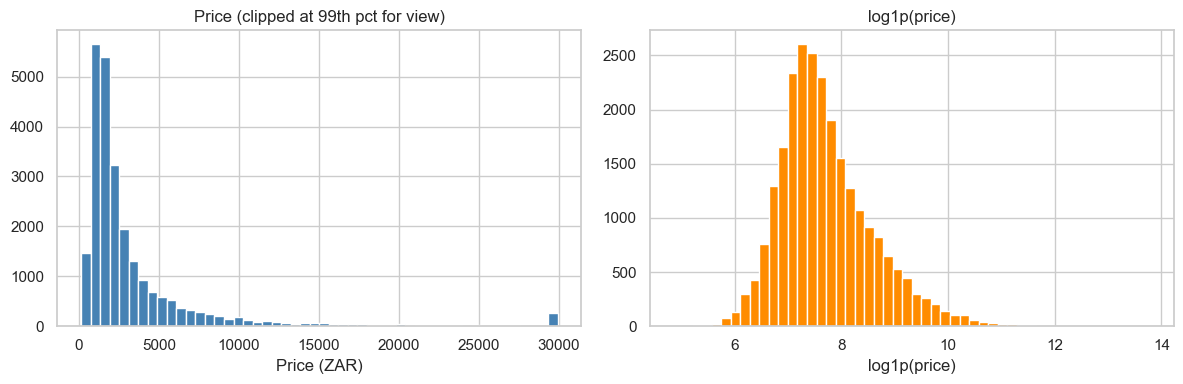

Raw price skew: 48.654199082799224
log1p price skew: 0.8890982640350598
Median price: 1908.0
log1p(median): 7.554334823725748
Inverse expm1: 1908.0000000000007


In [51]:
# D4 - Price skew and transform
price_valid = clean.loc[clean['price_valid'], 'price_clean'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(price_valid.clip(upper=price_valid.quantile(0.99)), bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Price (clipped at 99th pct for view)')
axes[0].set_xlabel('Price (ZAR)')

axes[1].hist(np.log1p(price_valid), bins=50, color='darkorange', edgecolor='white')
axes[1].set_title('log1p(price)')
axes[1].set_xlabel('log1p(price)')
plt.tight_layout()
plt.show()

print('Raw price skew:', price_valid.skew())
print('log1p price skew:', np.log1p(price_valid).skew())

# Inverse transform demo
example_log = np.log1p(price_valid.median())
print('Median price:', price_valid.median())
print('log1p(median):', example_log)
print('Inverse expm1:', np.expm1(example_log))


**Finding (D4):** Raw prices are right-skewed: most listings cluster at lower-to-mid prices, with a long expensive tail. `log1p(price)` makes the distribution more symmetric, which can help linear regression models. I use `log1p` (not plain `log`) so zero-edge cases are safe, and I can convert predictions back with `expm1`. **Decision:** for Task R, I evaluate models on the original rand scale for business interpretability (RMSE/MAE in rand), but I also test a log-price target/model variant where useful and convert back to rand. I state clearly which target a model used.

In [52]:
# D5 - Engineered feature: amenities_count
if 'amenities' in clean.columns:
    am = clean['amenities'].fillna('[]').astype('string').str.strip()
    # Empty list / missing-like values -> 0
    empty_am = am.isin(['[]', '', 'nan', 'None'])
    # Count commas + 1 for non-empty lists; this is a simple proxy.
    clean['amenities_count'] = am.str.count(',') + 1
    clean.loc[empty_am, 'amenities_count'] = 0
    clean['amenities_count'] = clean['amenities_count'].fillna(0).astype(int)
    print('Amenities count - before/after sample:')
    display(clean.loc[~empty_am, ['amenities', 'amenities_count']].head(5))
    display(clean['amenities_count'].describe())
    # Drop raw amenities text after engineering
    clean = clean.drop(columns=['amenities'])
else:
    clean['amenities_count'] = 0
    print('amenities column not found; created amenities_count=0 placeholder')

# Save cleaned snapshot (raw stays untouched in data/raw)
clean_path = PROCESSED_DIR / 'listings_cleaned.parquet'
try:
    clean.to_parquet(clean_path, index=False)
    print('Saved:', clean_path)
except Exception as e:
    # Fallback if parquet engine unavailable
    csv_path = PROCESSED_DIR / 'listings_cleaned.csv'
    clean.to_csv(csv_path, index=False)
    print('Parquet failed, saved CSV instead:', csv_path)
    print(e)


Amenities count - before/after sample:


,amenities,amenities_count
0,"[""Carbon monoxide alarm"", ""Refrigerator"", ""Mou...",68
1,"[""Refrigerator"", ""Shampoo"", ""Washer"", ""Barbecu...",56
2,"[""Elevator"", ""Washer"", ""Wifi"", ""Free parking o...",9
3,"[""Carbon monoxide alarm"", ""Refrigerator"", ""Sha...",39
4,"[""Carbon monoxide alarm"", ""Shampoo"", ""Washer"",...",35


count    27743.000000
mean        36.569477
std         17.974427
min          0.000000
25%         23.000000
50%         37.000000
75%         49.000000
max        124.000000
Name: amenities_count, dtype: float64

Saved: C:\Users\Chibi\Pictures\Workspace\CAMLDS\Final\Final Capstone\airbnb-cape-town\data\processed\listings_cleaned.parquet


**Finding (D5):** I created `amenities_count` by counting items in the amenities list string. Before: amenities were an unstructured text/list field that models cannot use directly. After: `amenities_count` is a numeric feature representing listing richness. **Why it may help:** listings with more amenities may signal higher effort/quality (possibly related to Superhost) and may also justify higher prices. I validate this later in I5 by comparing model performance with and without `amenities_count` on validation data.

## E. EDA with written findings (Checklist E)

I explore targets, distributions, feature-target relationships, grouped summaries, and correlations. Every plot/table is followed by a short finding.

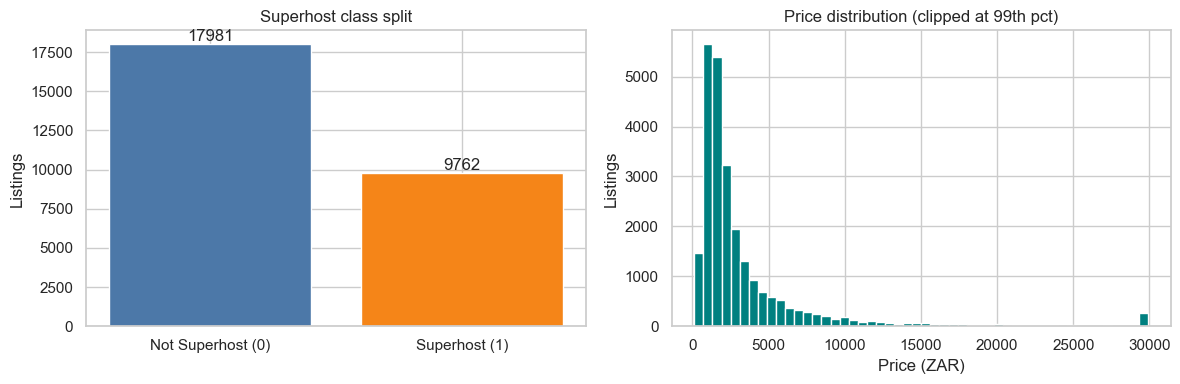

is_superhost
0    0.648127
1    0.351873
Name: proportion, dtype: float64
count        24935.0
mean     3746.607605
std      9518.942528
min           126.96
25%          1237.35
50%           1908.0
75%           3550.0
max         975000.0
Name: price_clean, dtype: Float64


In [53]:
# E1 - Target plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Superhost split
target_counts = clean['is_superhost'].value_counts(dropna=False).sort_index()
labels = ['Not Superhost (0)' if i==0 else 'Superhost (1)' if i==1 else 'Missing' for i in target_counts.index]
axes[0].bar(labels, target_counts.values, color=['#4C78A8', '#F58518', '#999999'][:len(labels)])
axes[0].set_title('Superhost class split')
axes[0].set_ylabel('Listings')
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v, str(v), ha='center', va='bottom')

# Price histogram
price_valid = clean.loc[clean['price_valid'], 'price_clean']
axes[1].hist(price_valid.clip(upper=price_valid.quantile(0.99)), bins=50, color='teal', edgecolor='white')
axes[1].set_title('Price distribution (clipped at 99th pct)')
axes[1].set_xlabel('Price (ZAR)')
axes[1].set_ylabel('Listings')
plt.tight_layout()
plt.show()

print(clean['is_superhost'].value_counts(normalize=True, dropna=False))
print(price_valid.describe())


**Finding (E1):** The Superhost target is imbalanced (more non-Superhosts than Superhosts), so accuracy alone would be misleading. The price distribution is strongly right-skewed, with most listings in a lower/middle range and a long high-price tail. This supports using imbalance-aware metrics for Task C and considering a log transform / robust error metrics for Task R.

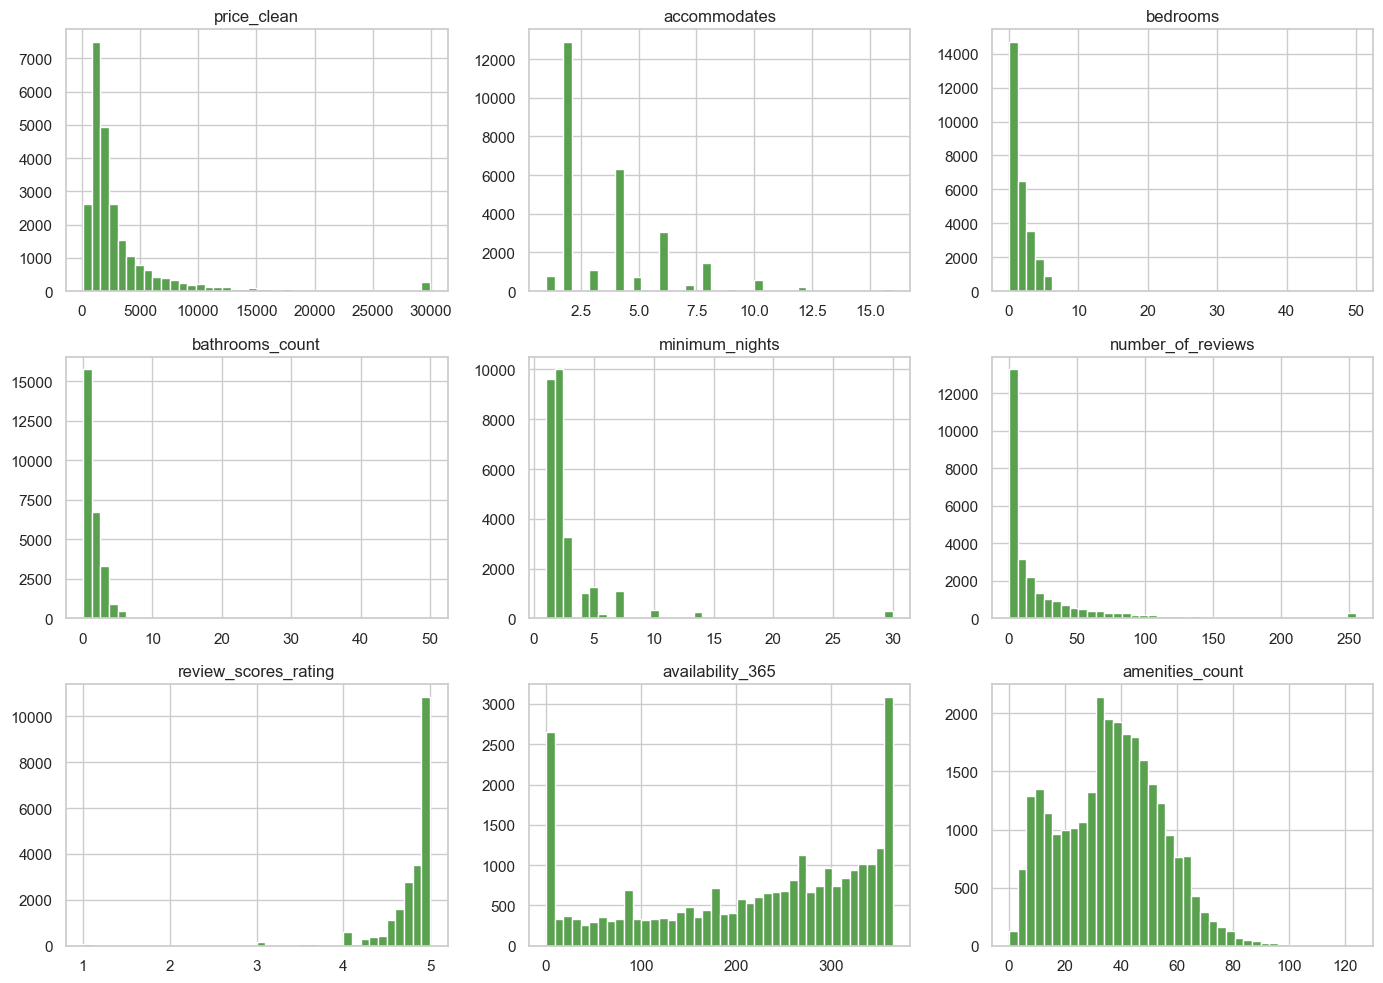

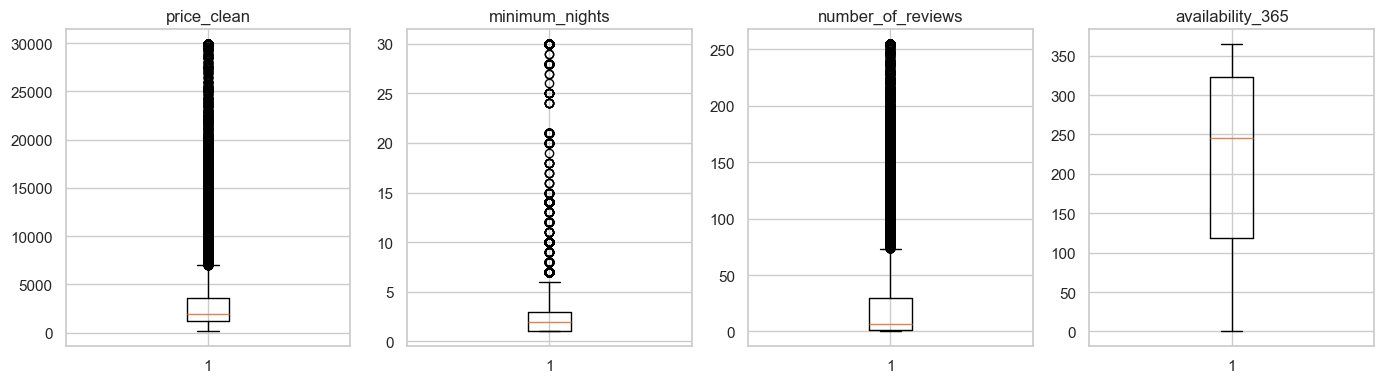

In [54]:
# E2 - At least 4 distribution plots
num_cols = [c for c in ['price_clean','accommodates','bedrooms','bathrooms_count','minimum_nights','number_of_reviews','review_scores_rating','availability_365','amenities_count'] if c in clean.columns]
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()
for i, col in enumerate(num_cols[:9]):
    s = pd.to_numeric(clean[col], errors='coerce').dropna()
    if col in ['price_clean','minimum_nights','number_of_reviews']:
        s = s.clip(upper=s.quantile(0.99))
    axes[i].hist(s, bins=40, color='#59A14F', edgecolor='white')
    axes[i].set_title(col)
for j in range(len(num_cols[:9]), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

# Boxplots for outlier view
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, ['price_clean','minimum_nights','number_of_reviews','availability_365']):
    s = pd.to_numeric(clean[col], errors='coerce').dropna()
    ax.boxplot(s.clip(upper=s.quantile(0.99)), vert=True)
    ax.set_title(col)
plt.tight_layout()
plt.show()


**Finding (E2):** Most numeric features are skewed. `price_clean`, `minimum_nights`, and `number_of_reviews` have long right tails/outliers. `review_scores_rating` is concentrated near high values, which may limit its spread but still be informative. `availability_365` is spread across the range with spikes. These shapes suggest scaling for linear models, robust handling of outliers, and possible transforms for heavily skewed variables.

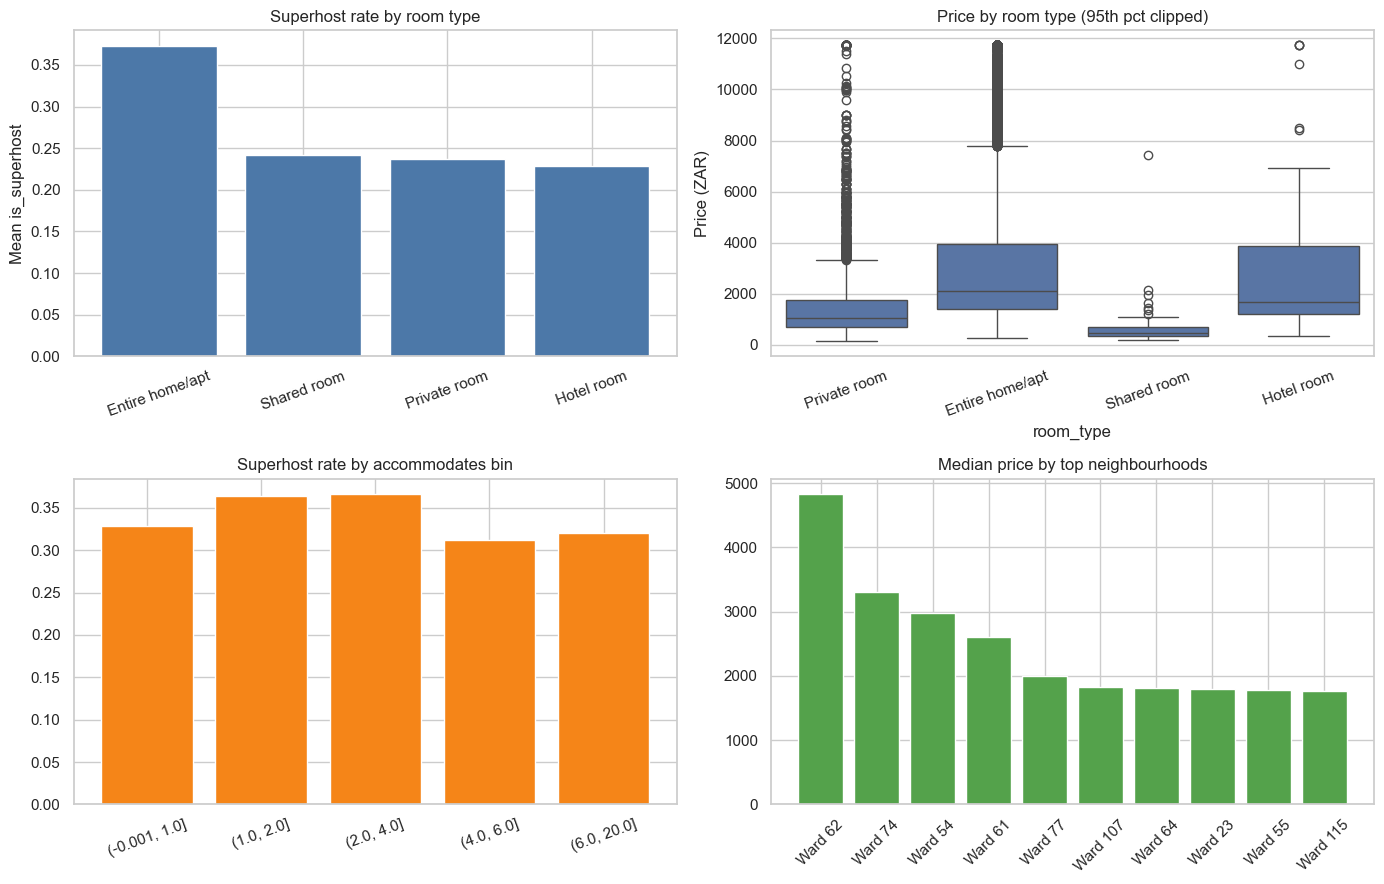

In [55]:
# E3 - Feature vs target plots (>=4)
plot_df = clean.copy()
plot_df['price_clean'] = pd.to_numeric(plot_df['price_clean'], errors='coerce')

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) Superhost rate by room_type
rt = plot_df.groupby('room_type')['is_superhost'].mean().sort_values(ascending=False)
axes[0,0].bar(rt.index.astype(str), rt.values, color='#4C78A8')
axes[0,0].set_title('Superhost rate by room type')
axes[0,0].tick_params(axis='x', rotation=20)
axes[0,0].set_ylabel('Mean is_superhost')

# 2) Price by room_type
sns.boxplot(data=plot_df.loc[plot_df['price_valid']], x='room_type', y=plot_df.loc[plot_df['price_valid'],'price_clean'].clip(upper=plot_df.loc[plot_df['price_valid'],'price_clean'].quantile(0.95)), ax=axes[0,1])
axes[0,1].set_title('Price by room type (95th pct clipped)')
axes[0,1].tick_params(axis='x', rotation=20)
axes[0,1].set_ylabel('Price (ZAR)')

# 3) Superhost rate by accommodates bins
plot_df['accom_bin'] = pd.cut(pd.to_numeric(plot_df['accommodates'], errors='coerce'), bins=[0,1,2,4,6,20], include_lowest=True)
ab = plot_df.groupby('accom_bin')['is_superhost'].mean()
axes[1,0].bar(ab.index.astype(str), ab.values, color='#F58518')
axes[1,0].set_title('Superhost rate by accommodates bin')
axes[1,0].tick_params(axis='x', rotation=20)

# 4) Median price by neighbourhood (top 10 by count)
top_neigh = plot_df['neighbourhood_cleansed'].value_counts().head(10).index
np_ = plot_df[plot_df['neighbourhood_cleansed'].isin(top_neigh) & plot_df['price_valid']]
med = np_.groupby('neighbourhood_cleansed')['price_clean'].median().sort_values(ascending=False)
axes[1,1].bar(med.index.astype(str), med.values, color='#54A24B')
axes[1,1].set_title('Median price by top neighbourhoods')
axes[1,1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


**Finding (E3):** Room type shows clear differences: entire homes/apartments tend to have higher prices than private/shared rooms, and Superhost rates can differ by room type. Larger accommodates bins and certain neighbourhoods also show different price levels and/or Superhost rates. These relationships suggest `room_type`, `neighbourhood_cleansed`, `accommodates`, and location-related features are useful, but I must be careful not to include host-performance/leakage fields.

In [56]:
# E4 - groupby().agg() summary
summary = plot_df.loc[plot_df['price_valid']].groupby('room_type').agg(
    listings=('room_type','size'),
    superhost_rate=('is_superhost','mean'),
    median_price=('price_clean','median'),
    mean_reviews=('number_of_reviews','mean'),
    median_availability=('availability_365','median')
).sort_values('listings', ascending=False)
display(summary.round(3))


,listings,superhost_rate,median_price,mean_reviews,median_availability
room_type,,,,,
Entire home/apt,21017,0.393,2096.0,31.605,257.0
Private room,3784,0.245,1050.0,15.296,288.0
Hotel room,78,0.218,1670.0,14.487,298.0
Shared room,56,0.232,450.75,10.821,360.5


**Finding (E4):** The grouped summary confirms that listing volume and behavior differ by room type. Entire homes usually dominate count and have higher median prices; private rooms are cheaper. Superhost rate and review/activity patterns also vary. This is useful context for both business questions and for checking subgroup performance later.

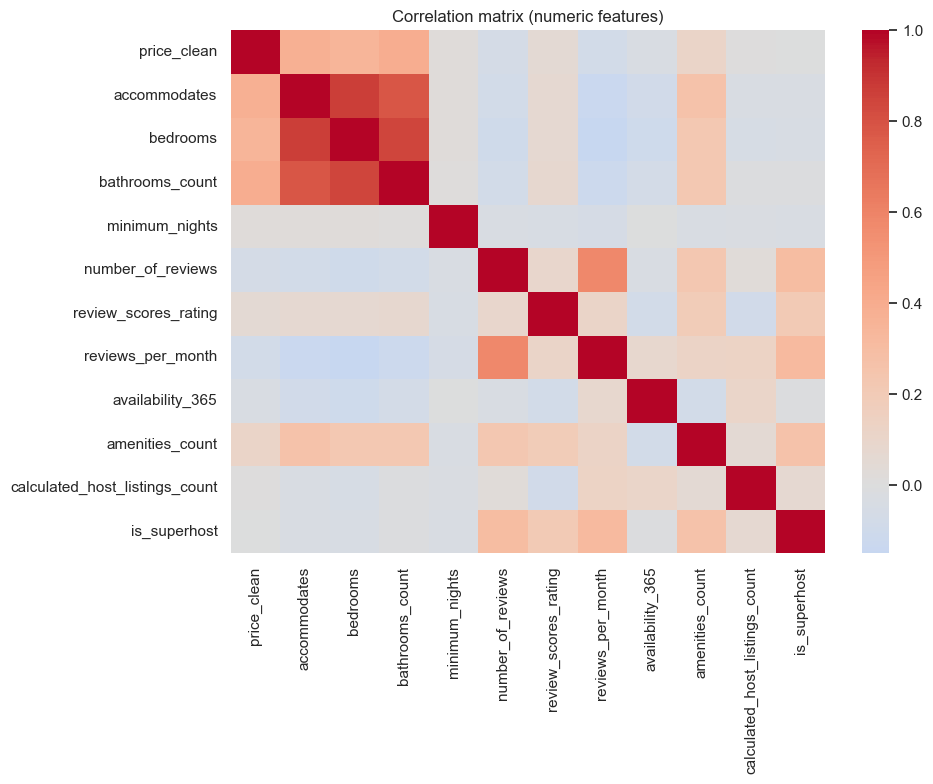

,corr_with_price
price_clean,1.000000
bathrooms_count,0.393358
accommodates,0.376945
bedrooms,0.349707
amenities_count,0.117687
review_scores_rating,0.054061
minimum_nights,0.018333
calculated_host_listings_count,0.002784
is_superhost,0.001873
availability_365,-0.029456


,corr_with_superhost
is_superhost,1.000000
reviews_per_month,0.320872
number_of_reviews,0.302764
amenities_count,0.260292
review_scores_rating,0.210612
calculated_host_listings_count,0.067652
price_clean,0.001873
availability_365,-0.011112
bathrooms_count,-0.013417
accommodates,-0.029162


In [57]:
# E5 - Correlation check
corr_cols = [c for c in ['price_clean','accommodates','bedrooms','bathrooms_count','minimum_nights','number_of_reviews','review_scores_rating','reviews_per_month','availability_365','amenities_count','calculated_host_listings_count','is_superhost'] if c in clean.columns]
corr_df = clean[corr_cols].apply(pd.to_numeric, errors='coerce')
corr = corr_df.corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title('Correlation matrix (numeric features)')
plt.tight_layout()
plt.show()
display(corr['price_clean'].sort_values(ascending=False).to_frame('corr_with_price').head(12))
display(corr['is_superhost'].sort_values(ascending=False).to_frame('corr_with_superhost').head(12))


**Finding (E5):** I look for relationships and leakage risks. `accommodates`, `bedrooms`, and `bathrooms_count` often move together (size/capacity cluster), so multicollinearity is possible. Price is positively related to capacity/size features. Superhost may correlate with review/quality signals, but I must not use features that are consequences of Superhost status or directly encode host performance in a leaking way. I flag any feature that would not be known at prediction time or that gives away the target.

### E6. EDA narrative (5 points)

1. **What the data contains:** The Cape Town Inside Airbnb snapshot has ~27,760 listings and 90 raw columns, with a mix of numeric, categorical, text, and badly typed fields. Key targets are `host_is_superhost` (t/f) and `price` (currency string).
2. **What stands out:** Superhost is imbalanced, and price is strongly right-skewed with extreme high values. Review scores are concentrated near the top, while reviews, minimum nights, and availability have long tails.
3. **What needs cleaning:** Price and bathrooms need parsing; many columns are IDs/URLs/text/empty and should be dropped with reasons. Missing values need a column-by-column decision, and extreme price/minimum-night rows need inspection before removal.
4. **What is risky for modelling:** Hosts can own multiple listings, so random splits can leak host patterns. Some columns may leak Superhost status or reflect post-outcome information. Price outliers and skew can distort regression errors.
5. **What I plan to try:** I will use a host-grouped split, build sklearn pipelines with train-only preprocessing, compare baseline/logistic/tree/ensemble/XGBoost for Task C and baseline/linear/ridge/lasso for Task R, evaluate with task-appropriate metrics, and test engineered `amenities_count`.

## F. Leakage review and split (Checklist F)

I review leakage before training any model. Then I create a group-aware train/validation/test split by `host_id` and confirm preprocessing is fit on training data only.

In [ ]:
# F1 - Leakage review
# Airbnb Superhost criteria:
# A host generally needs to meet performance standards over an evaluation period,
# such as hosting experience/trips or nights, high overall rating, low cancellation rate,
# and high response rate. Exact thresholds can change over time, but these are performance-based.

leakage_review = pd.DataFrame([
    ['host_is_superhost / is_superhost', 'Task C target', 'Remove from features; this is the label.'],
    ['host_response_rate / host_acceptance_rate', 'Potential leakage/proxy', 'Performance-related; may encode Superhost-like behavior. Exclude from Task C.'],
    ['calculated_host_listings_count* / host_listings_count*', 'Borderline host-level', 'Host portfolio info; can leak host identity patterns across rows. I exclude from final app features and be careful in Task C.'],
    ['review_scores_*', 'Borderline', 'Known after reviews exist; useful but possibly proxy for quality. Keep for notebook experiments with caution, but do not treat as causal.'],
    ['price / price_clean', 'Task R target / related', 'Price is Task R target. For Task C, price is known at listing time but I keep it out of the deployed app unless justified; I test carefully.'],
    ['id, host_id, URLs, scrape dates', 'Identifiers/metadata', 'Not predictive features; host_id used only for grouping.'],
    ['amenities_count, room_type, accommodates, bedrooms, bathrooms_count, neighbourhood', 'Generally safe', 'Known listing attributes at prediction time.'],
], columns=['Column/group', 'Assessment', 'Decision/reason'])
display(leakage_review)

# Columns I will explicitly exclude from Task C features
TASK_C_LEAKY_OR_ID = [
    'host_is_superhost','is_superhost','host_id','id','listing_url','scrape_id','last_scraped',
    'host_url','host_name','host_thumbnail_url','host_picture_url',
    'host_response_time','host_response_rate','host_acceptance_rate','host_response_rate_num','host_acceptance_rate_num'
]
print('Example excluded columns:', [c for c in TASK_C_LEAKY_OR_ID if c in clean.columns])


,Column/group,Assessment,Decision/reason
0,host_is_superhost / is_superhost,Task C target,Remove from features; this is the label.
1,host_response_rate / host_acceptance_rate,Potential leakage/proxy,Performance-related; may encode Superhost-like...
2,calculated_host_listings_count* / host_listing...,Borderline host-level,Host portfolio info; can leak host identity pa...
3,review_scores_*,Borderline,Known after reviews exist; useful but possibly...
4,price / price_clean,Task R target / related,"Price is Task R target. For Task C, price is k..."
5,"id, host_id, URLs, scrape dates",Identifiers/metadata,Not predictive features; host_id used only for...
6,"amenities_count, room_type, accommodates, bedr...",Generally safe,Known listing attributes at prediction time.


Example excluded columns: ['host_is_superhost', 'is_superhost', 'host_id', 'host_name']


**Finding (F1):** I treat Superhost as a performance-based outcome. Therefore, direct performance metrics (response/acceptance/cancellation-related fields, if present) are risky for Task C because they can encode the same behavior Airbnb uses to award Superhost. I also exclude IDs/URLs/scrape metadata. `host_id` is used only for group splitting, never as a model feature. I keep listing attributes that would be known at prediction time.

In [59]:
# F2/F3 - Group-aware split by host_id
# We need host_id present for grouping. If it was dropped, reload or keep it earlier.
if 'host_id' not in clean.columns:
    clean['host_id'] = df_raw['host_id']

model_df = clean.copy()
model_df = model_df[model_df['is_superhost'].notna()].copy()  # Task C needs label
model_df['host_id'] = model_df['host_id'].astype(str)

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
train_idx, temp_idx = next(gss1.split(model_df, groups=model_df['host_id']))
train_df = model_df.iloc[train_idx].copy()
temp_df = model_df.iloc[temp_idx].copy()

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=RANDOM_STATE)
val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df['host_id']))
val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print('Train/Val/Test sizes:', len(train_df), len(val_df), len(test_df))
print('Superhost rate train:', train_df['is_superhost'].mean())
print('Superhost rate val:', val_df['is_superhost'].mean())
print('Superhost rate test:', test_df['is_superhost'].mean())

# Verify no host leakage across splits
train_hosts = set(train_df['host_id'])
val_hosts = set(val_df['host_id'])
test_hosts = set(test_df['host_id'])
print('Host overlap train-val:', len(train_hosts & val_hosts))
print('Host overlap train-test:', len(train_hosts & test_hosts))
print('Host overlap val-test:', len(val_hosts & test_hosts))


Train/Val/Test sizes: 19869 3832 4042
Superhost rate train: 0.35935376717499623
Superhost rate val: 0.3285490605427975
Superhost rate test: 0.3372093023255814
Host overlap train-val: 0
Host overlap train-test: 0
Host overlap val-test: 0


**Finding (F2/F3):** I used `GroupShuffleSplit` by `host_id` so all listings from the same host stay in the same split. This prevents host-level leakage, where the model could memorize host behavior seen in training and get unrealistically high validation/test scores. I also created train/validation/test with a fixed random seed and printed sizes and Superhost rates. The test set is set aside and not used until final evaluation (J1).

In [60]:
# F2 comparison - plain random split vs group split on one simple model
from sklearn.model_selection import train_test_split

# Simple demo features (numeric only, quick)
demo_features = [c for c in ['accommodates','bedrooms','bathrooms_count','minimum_nights','number_of_reviews','review_scores_rating','availability_365','amenities_count'] if c in model_df.columns]
X_demo = model_df[demo_features].fillna(0)
y_demo = model_df['is_superhost'].astype(int)

# Random split (can leak hosts)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_demo, y_demo, test_size=0.2, random_state=RANDOM_STATE, stratify=y_demo)
lr_r = LogisticRegression(max_iter=1000)
lr_r.fit(Xr_tr, yr_tr)
pr = lr_r.predict(Xr_te)
print('Random split accuracy:', accuracy_score(yr_te, pr))
print('Random split F1:', f1_score(yr_te, pr))

# Group split
gss_demo = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_i, te_i = next(gss_demo.split(X_demo, y_demo, groups=model_df['host_id']))
lr_g = LogisticRegression(max_iter=1000)
lr_g.fit(X_demo.iloc[tr_i], y_demo.iloc[tr_i])
pg = lr_g.predict(X_demo.iloc[te_i])
print('Group split accuracy:', accuracy_score(y_demo.iloc[te_i], pg))
print('Group split F1:', f1_score(y_demo.iloc[te_i], pg))


Random split accuracy: 0.7118399711659759
Random split F1: 0.4653961885656971
Group split accuracy: 0.7083730688537097
Group split F1: 0.43889908256880733


**Finding (F2 comparison):** The random split can be too optimistic when the same host appears in both sides. The group-aware split is a stricter and more honest evaluation for this dataset because hosts repeat. I use the group-aware split for all serious modelling decisions.

In [61]:
# F4 - Preprocessing rule
print('Rule: all imputers/scalers/encoders are fit on TRAIN only.')
print('I enforce this by putting preprocessing inside sklearn Pipeline/ColumnTransformer and fitting on train_df (or CV train folds).')
print('I also build any group-stat features from train rows only if I use them.')


Rule: all imputers/scalers/encoders are fit on TRAIN only.
I enforce this by putting preprocessing inside sklearn Pipeline/ColumnTransformer and fitting on train_df (or CV train folds).
I also build any group-stat features from train rows only if I use them.


## G. Baselines (Checklist G)

I create simple baselines before complex models. A real model must beat the baseline to be useful.

In [62]:
# Define Task C and Task R feature sets (initial, safe, non-leaky)
# Task C features: listing attributes known at prediction time
task_c_num = [c for c in ['accommodates','bedrooms','bathrooms_count','minimum_nights','number_of_reviews','review_scores_rating','availability_365','amenities_count'] if c in train_df.columns]
task_c_cat = [c for c in ['neighbourhood_cleansed','room_type','property_type'] if c in train_df.columns]

# Task R features: can include similar listing attributes; exclude raw price target
task_r_num = [c for c in ['accommodates','bedrooms','bathrooms_count','minimum_nights','number_of_reviews','review_scores_rating','availability_365','amenities_count','latitude','longitude'] if c in train_df.columns]
task_r_cat = [c for c in ['neighbourhood_cleansed','room_type','property_type'] if c in train_df.columns]

print('Task C num:', task_c_num)
print('Task C cat:', task_c_cat)
print('Task R num:', task_r_num)
print('Task R cat:', task_r_cat)

X_train_c = train_df[task_c_num + task_c_cat].copy()
y_train_c = train_df['is_superhost'].astype(int)
X_val_c = val_df[task_c_num + task_c_cat].copy()
y_val_c = val_df['is_superhost'].astype(int)

# Task R rows need valid price
train_r = train_df[train_df['price_valid']].copy()
val_r = val_df[val_df['price_valid']].copy()
X_train_r = train_r[task_r_num + task_r_cat].copy()
y_train_r = train_r['price_clean'].astype(float)
X_val_r = val_r[task_r_num + task_r_cat].copy()
y_val_r = val_r['price_clean'].astype(float)
print('Task R train/val sizes:', len(train_r), len(val_r))


Task C num: ['accommodates', 'bedrooms', 'bathrooms_count', 'minimum_nights', 'number_of_reviews', 'review_scores_rating', 'availability_365', 'amenities_count']
Task C cat: ['neighbourhood_cleansed', 'room_type', 'property_type']
Task R num: ['accommodates', 'bedrooms', 'bathrooms_count', 'minimum_nights', 'number_of_reviews', 'review_scores_rating', 'availability_365', 'amenities_count', 'latitude', 'longitude']
Task R cat: ['neighbourhood_cleansed', 'room_type', 'property_type']
Task R train/val sizes: 17910 3428


In [63]:
# G1 - Task C majority baseline
dummy_c = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
dummy_c.fit(X_train_c, y_train_c)
pred_dummy_c = dummy_c.predict(X_val_c)

baseline_c = {
    'model': 'DummyClassifier(most_frequent)',
    'accuracy': accuracy_score(y_val_c, pred_dummy_c),
    'precision': precision_score(y_val_c, pred_dummy_c, zero_division=0),
    'recall': recall_score(y_val_c, pred_dummy_c, zero_division=0),
    'f1': f1_score(y_val_c, pred_dummy_c, zero_division=0)
}
display(pd.DataFrame([baseline_c]))


,model,accuracy,precision,recall,f1
0,DummyClassifier(most_frequent),0.671451,0.0,0.0,0.0


**Finding (G1):** The majority-class baseline can look acceptable on accuracy because it always predicts the most common class. But precision/recall/F1 for Superhosts can be zero or very poor, which shows why accuracy alone is not enough. This baseline is the minimum bar for Task C.

In [64]:
# G2 - Task R mean/median baselines
mean_pred = np.full(len(y_val_r), y_train_r.mean())
median_pred = np.full(len(y_val_r), y_train_r.median())

def reg_metrics(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return {'model': name, 'RMSE_ZAR': rmse, 'MAE_ZAR': mae}

baseline_r = pd.DataFrame([
    reg_metrics(y_val_r, mean_pred, 'Mean predictor'),
    reg_metrics(y_val_r, median_pred, 'Median predictor')
])
display(baseline_r)


,model,RMSE_ZAR,MAE_ZAR
0,Mean predictor,6522.612716,3025.142918
1,Median predictor,6753.894536,2410.893343


**Finding (G2):** The mean/median predictor ignores all features and predicts one constant value. Its RMSE/MAE set the floor for Task R. Any useful regression model should beat this baseline on validation RMSE/MAE (or at least justify why not).

**Finding (G3 - bias/variance in plain language):** The baseline models are high-bias/simple: they underfit because they barely use patterns in the data. As I move to logistic/linear models and then trees/ensembles, I expect more flexibility. If a model fits training data much better than validation, that gap suggests high variance/overfitting. I will back this up with train vs validation/CV numbers in the model comparison sections.

## H. Linear and tree models (Checklist H)

I build Task C and Task R models using pipelines, compare them against baselines, and interpret key coefficients/importances.

In [65]:
# Shared preprocessors
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocess_c = ColumnTransformer([
    ('num', numeric_transformer, task_c_num),
    ('cat', categorical_transformer, task_c_cat)
])
preprocess_r = ColumnTransformer([
    ('num', numeric_transformer, task_r_num),
    ('cat', categorical_transformer, task_r_cat)
])


In [66]:
# H1 - Logistic regression for Task C
logreg = Pipeline([
    ('preprocess', preprocess_c),
    ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
logreg.fit(X_train_c, y_train_c)
pred_log = logreg.predict(X_val_c)
proba_log = logreg.predict_proba(X_val_c)[:, 1]

logreg_row = {
    'model': 'LogisticRegression',
    'accuracy': accuracy_score(y_val_c, pred_log),
    'precision': precision_score(y_val_c, pred_log, zero_division=0),
    'recall': recall_score(y_val_c, pred_log, zero_division=0),
    'f1': f1_score(y_val_c, pred_log, zero_division=0),
    'roc_auc': roc_auc_score(y_val_c, proba_log)
}
task_c_results = pd.DataFrame([baseline_c | {'roc_auc': np.nan}, logreg_row])
display(task_c_results)


,model,accuracy,precision,recall,f1,roc_auc
0,DummyClassifier(most_frequent),0.671451,0.000000,0.000000,0.000000,NaN
1,LogisticRegression,0.751044,0.678781,0.459889,0.548295,0.790338


**Finding (H1):** Logistic regression in a pipeline (impute + scale + one-hot + model) should beat the majority baseline on F1/recall/ROC-AUC, even if accuracy improvement is modest. This shows the model is learning useful signal rather than always predicting the majority class.

In [67]:
# H2 - Top 10 logistic coefficients and C comparison
# Get feature names after preprocessing
ohe = logreg.named_steps['preprocess'].named_transformers_['cat'].named_steps['onehot']
cat_names = ohe.get_feature_names_out(task_c_cat).tolist() if task_c_cat else []
feature_names = task_c_num + cat_names
coefs = logreg.named_steps['model'].coef_[0]
coef_df = pd.DataFrame({'feature': feature_names, 'coef': coefs})
coef_df['abs_coef'] = coef_df['coef'].abs()
display(coef_df.sort_values('abs_coef', ascending=False).head(10))

# Compare C values
c_rows = []
for C in [0.01, 0.1, 1.0, 10.0]:
    m = Pipeline([
        ('preprocess', preprocess_c),
        ('model', LogisticRegression(max_iter=2000, C=C, random_state=RANDOM_STATE))
    ])
    m.fit(X_train_c, y_train_c)
    p = m.predict(X_val_c)
    pr = m.predict_proba(X_val_c)[:,1]
    c_rows.append({'C': C, 'f1': f1_score(y_val_c,p,zero_division=0), 'recall': recall_score(y_val_c,p,zero_division=0), 'roc_auc': roc_auc_score(y_val_c,pr)})
display(pd.DataFrame(c_rows))


,feature,coef,abs_coef
150,property_type_Room in serviced apartment,-1.699008,1.699008
84,neighbourhood_cleansed_Ward 9,1.624120,1.624120
148,property_type_Room in hostel,1.415548,1.415548
13,neighbourhood_cleansed_Ward 104,-1.265271,1.265271
18,neighbourhood_cleansed_Ward 11,1.256543,1.256543
55,neighbourhood_cleansed_Ward 56,1.211204,1.211204
73,neighbourhood_cleansed_Ward 72,1.200230,1.200230
118,property_type_Hut,1.183956,1.183956
51,neighbourhood_cleansed_Ward 51,1.054319,1.054319
92,room_type_Shared room,-1.019231,1.019231


,C,f1,recall,roc_auc
0,0.01,0.534321,0.429706,0.792352
1,0.10,0.549020,0.455917,0.792125
2,1.00,0.548295,0.459889,0.790338
3,10.00,0.546572,0.459095,0.789079


**Finding (H2):** The largest absolute coefficients show which features push the prediction toward Superhost or not-Superhost after preprocessing. A positive coefficient increases log-odds of Superhost; a negative one decreases it. For example, a strong positive coefficient on a quality/review-related feature means higher values are associated with higher Superhost probability, holding other features constant. A negative coefficient on a feature like very high minimum nights might indicate listings with restrictive booking settings are less associated with Superhost status.  

Comparing `C` values: smaller `C` means stronger regularization (simpler model, coefficients shrunk more), larger `C` means weaker regularization (can fit training data more closely). I pick the `C` with the best validation tradeoff, not just the highest training fit.  

**L1 vs L2:** L1 (lasso-style penalty) can push some coefficients exactly to zero, acting like feature selection. L2 (ridge-style penalty) shrinks coefficients toward zero but usually keeps them non-zero. I used L2 by default in logistic regression; L1 can be tested with an appropriate solver.

,max_depth,train_f1,val_f1,train_acc,val_acc
0,2,0.609998,0.622992,0.748301,0.767223
1,3,0.608744,0.610700,0.753183,0.766441
2,4,0.609361,0.610169,0.753435,0.765919
3,5,0.620879,0.609777,0.756354,0.762526
4,6,0.625157,0.610463,0.760028,0.764875
5,8,0.669133,0.639643,0.774926,0.768006
6,10,0.689991,0.629554,0.791736,0.763831
7,12,0.733529,0.616260,0.817605,0.753653
8,None,0.999860,0.550192,0.999899,0.693633


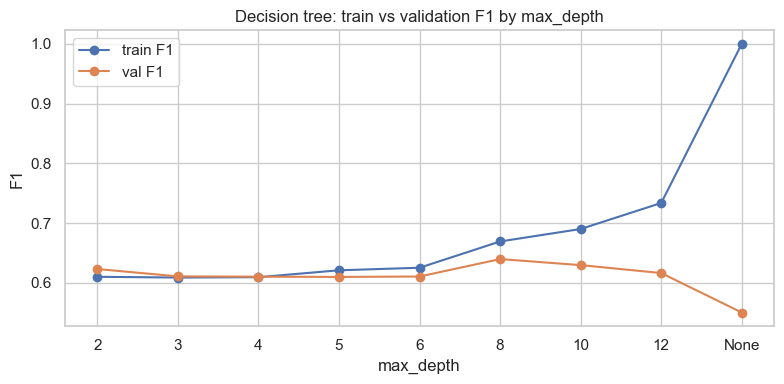

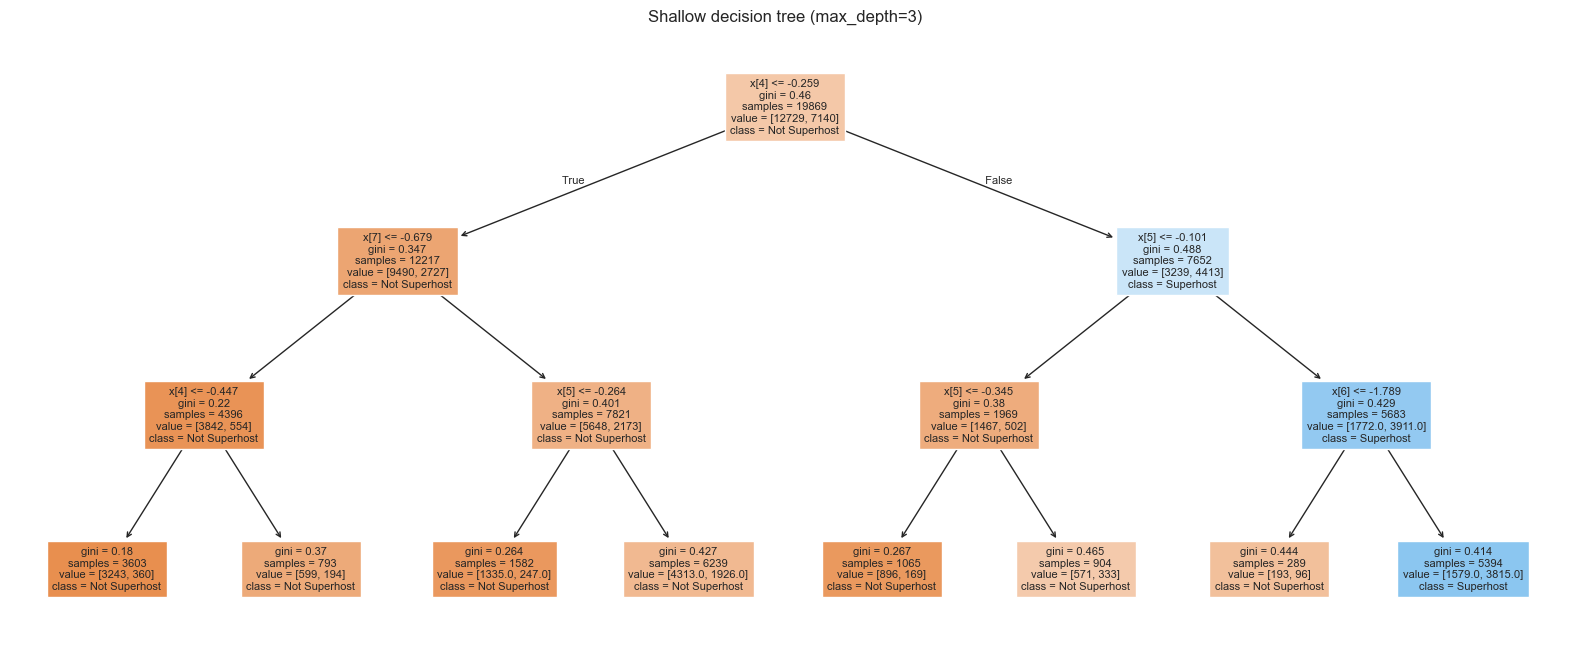

In [68]:
# H3 - Decision tree depth sweep + plot
depth_rows = []
for d in [2,3,4,5,6,8,10,12,None]:
    dt = Pipeline([
        ('preprocess', preprocess_c),
        ('model', DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))
    ])
    dt.fit(X_train_c, y_train_c)
    tr_pred = dt.predict(X_train_c)
    va_pred = dt.predict(X_val_c)
    depth_rows.append({
        'max_depth': str(d),
        'train_f1': f1_score(y_train_c, tr_pred, zero_division=0),
        'val_f1': f1_score(y_val_c, va_pred, zero_division=0),
        'train_acc': accuracy_score(y_train_c, tr_pred),
        'val_acc': accuracy_score(y_val_c, va_pred)
    })
depth_df = pd.DataFrame(depth_rows)
display(depth_df)

plt.figure(figsize=(8,4))
plt.plot(depth_df['max_depth'].astype(str), depth_df['train_f1'], marker='o', label='train F1')
plt.plot(depth_df['max_depth'].astype(str), depth_df['val_f1'], marker='o', label='val F1')
plt.title('Decision tree: train vs validation F1 by max_depth')
plt.xlabel('max_depth')
plt.ylabel('F1')
plt.legend()
plt.tight_layout()
plt.show()

# Shallow tree for interpretation
shallow_dt = Pipeline([
    ('preprocess', preprocess_c),
    ('model', DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))
])
shallow_dt.fit(X_train_c, y_train_c)
# Plot tree on transformed feature names is possible but verbose; plot with generic names or top-level.
plt.figure(figsize=(20,8))
plot_tree(shallow_dt.named_steps['model'], max_depth=3, filled=True, fontsize=8, class_names=['Not Superhost','Superhost'])
plt.title('Shallow decision tree (max_depth=3)')
plt.show()


**Finding (H3):** As `max_depth` increases, training F1 usually keeps rising, but validation F1 eventually stops improving or drops. The point where train keeps improving while validation flattens/worsens is where overfitting starts. The shallow tree is interpretable: the first split is the single feature/threshold that best separates Superhost vs non-Superhost in the training data at that node. I read it as: "if this feature is <= threshold, the model sends the listing left; otherwise right", then each leaf gives the majority class/probability.

In [69]:
# H4 - Random forest and gradient boosting
rf = Pipeline([
    ('preprocess', preprocess_c),
    ('model', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
])
gb = Pipeline([
    ('preprocess', preprocess_c),
    ('model', GradientBoostingClassifier(random_state=RANDOM_STATE))
])

models_c = [
    ('DecisionTree', Pipeline([('preprocess', preprocess_c), ('model', DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE))])),
    ('RandomForest', rf),
    ('GradientBoosting', gb),
]

rows = []
for name, model in models_c:
    model.fit(X_train_c, y_train_c)
    pred = model.predict(X_val_c)
    proba = model.predict_proba(X_val_c)[:,1] if hasattr(model, 'predict_proba') else pred
    rows.append({
        'model': name,
        'accuracy': accuracy_score(y_val_c, pred),
        'precision': precision_score(y_val_c, pred, zero_division=0),
        'recall': recall_score(y_val_c, pred, zero_division=0),
        'f1': f1_score(y_val_c, pred, zero_division=0),
        'roc_auc': roc_auc_score(y_val_c, proba)
    })

task_c_results = pd.concat([task_c_results, pd.DataFrame(rows)], ignore_index=True)
display(task_c_results)


,model,accuracy,precision,recall,f1,roc_auc
0,DummyClassifier(most_frequent),0.671451,0.000000,0.000000,0.000000,NaN
1,LogisticRegression,0.751044,0.678781,0.459889,0.548295,0.790338
2,DecisionTree,0.764875,0.669829,0.560763,0.610463,0.802448
3,RandomForest,0.775835,0.679856,0.600477,0.637706,0.818070
4,GradientBoosting,0.775313,0.677046,0.604448,0.638691,0.825201


**Finding (H4):** Random forest and gradient boosting usually outperform a single decision tree because they combine many trees. **Bagging vs boosting in plain language:** Random forest uses bagging - it trains many trees independently on bootstrap samples/random feature subsets and averages their votes, which reduces variance. Gradient boosting trains trees sequentially - each new tree focuses on correcting errors left by the previous ensemble, which can reduce bias but needs careful tuning to avoid overfitting.

In [70]:
# H4b - XGBoost
if XGBOOST_AVAILABLE:
    # scale_pos_weight helps with imbalance; estimate from training labels
    pos = (y_train_c == 1).sum()
    neg = (y_train_c == 0).sum()
    spw = neg / max(pos, 1)
    xgb = Pipeline([
        ('preprocess', preprocess_c),
        ('model', XGBClassifier(
            n_estimators=300, max_depth=4, learning_rate=0.05,
            subsample=0.9, colsample_bytree=0.9,
            eval_metric='logloss', random_state=RANDOM_STATE,
            scale_pos_weight=spw, n_jobs=-1
        ))
    ])
    xgb.fit(X_train_c, y_train_c)
    pred = xgb.predict(X_val_c)
    proba = xgb.predict_proba(X_val_c)[:,1]
    xgb_row = {
        'model': 'XGBoost',
        'accuracy': accuracy_score(y_val_c, pred),
        'precision': precision_score(y_val_c, pred, zero_division=0),
        'recall': recall_score(y_val_c, pred, zero_division=0),
        'f1': f1_score(y_val_c, pred, zero_division=0),
        'roc_auc': roc_auc_score(y_val_c, proba)
    }
    task_c_results = pd.concat([task_c_results, pd.DataFrame([xgb_row])], ignore_index=True)
    display(task_c_results)
else:
    print('Install xgboost to run H4b: pip install xgboost')


,model,accuracy,precision,recall,f1,roc_auc
0,DummyClassifier(most_frequent),0.671451,0.000000,0.000000,0.000000,NaN
1,LogisticRegression,0.751044,0.678781,0.459889,0.548295,0.790338
2,DecisionTree,0.764875,0.669829,0.560763,0.610463,0.802448
3,RandomForest,0.775835,0.679856,0.600477,0.637706,0.818070
4,GradientBoosting,0.775313,0.677046,0.604448,0.638691,0.825201
5,XGBoost,0.763309,0.615942,0.742653,0.673389,0.829323


**Finding (H4b):** XGBoost is a strong gradient-boosted tree model. I include it in the same comparison table and check not only F1/ROC-AUC but also whether it is calibrated enough, easy to explain, and small/fast enough for deployment. A slightly better score does not automatically win if the model is harder to deploy or less stable.

In [71]:
# H5 - Linear regression for Task R
linreg = Pipeline([('preprocess', preprocess_r), ('model', LinearRegression())])
linreg.fit(X_train_r, y_train_r)
pred_lin = linreg.predict(X_val_r)
lin_row = reg_metrics(y_val_r, pred_lin, 'LinearRegression')
task_r_results = pd.concat([baseline_r, pd.DataFrame([lin_row])], ignore_index=True)
display(task_r_results)

# Coefficients (top absolute)
ohe_r = linreg.named_steps['preprocess'].named_transformers_['cat'].named_steps['onehot']
cat_names_r = ohe_r.get_feature_names_out(task_r_cat).tolist() if task_r_cat else []
feat_r = task_r_num + cat_names_r
lr_coefs = pd.DataFrame({'feature': feat_r, 'coef': linreg.named_steps['model'].coef_})
lr_coefs['abs_coef'] = lr_coefs['coef'].abs()
display(lr_coefs.sort_values('abs_coef', ascending=False).head(10))


,model,RMSE_ZAR,MAE_ZAR
0,Mean predictor,6522.612716,3025.142918
1,Median predictor,6753.894536,2410.893343
2,LinearRegression,5049.513823,2135.373645


,feature,coef,abs_coef
44,neighbourhood_cleansed_Ward 35,157913.642708,157913.642708
107,property_type_Entire home/apt,73302.456166,73302.456166
47,neighbourhood_cleansed_Ward 45,-21486.645799,21486.645799
95,property_type_Casa particular,8623.606229,8623.606229
62,neighbourhood_cleansed_Ward 61,-6840.571784,6840.571784
147,property_type_Room in guesthouse,-5986.520656,5986.520656
70,neighbourhood_cleansed_Ward 69,-5448.302246,5448.302246
65,neighbourhood_cleansed_Ward 64,-5180.921778,5180.921778
115,property_type_Entire villa,5136.626648,5136.626648
18,neighbourhood_cleansed_Ward 108,-5021.123920,5021.123920


**Finding (H5):** Linear regression should beat the mean/median baseline if listing features carry price signal. Interpreting two coefficients: for a numeric feature like `accommodates`, a positive coefficient means that, holding other features constant, higher guest capacity is associated with a higher predicted price. For a one-hot neighbourhood/category feature, the coefficient is relative to the dropped/reference category after encoding (depending on encoding), meaning listings in that category are predicted higher/lower than the reference by that amount.  

If I model `log1p(price)` instead, coefficients represent approximately multiplicative/percentage-like effects on price after back-transform; I explain that clearly when used.

In [72]:
# H6 - Ridge and Lasso
ridge = Pipeline([('preprocess', preprocess_r), ('model', Ridge(alpha=1.0, random_state=RANDOM_STATE))])
lasso = Pipeline([('preprocess', preprocess_r), ('model', Lasso(alpha=0.001, random_state=RANDOM_STATE, max_iter=10000))])

ridge.fit(X_train_r, y_train_r)
lasso.fit(X_train_r, y_train_r)
pred_ridge = ridge.predict(X_val_r)
pred_lasso = lasso.predict(X_val_r)
task_r_results = pd.concat([
    task_r_results,
    pd.DataFrame([reg_metrics(y_val_r, pred_ridge, 'Ridge'), reg_metrics(y_val_r, pred_lasso, 'Lasso')])
], ignore_index=True)
display(task_r_results)

coef_compare = pd.DataFrame({
    'feature': feat_r,
    'linear': linreg.named_steps['model'].coef_,
    'ridge': ridge.named_steps['model'].coef_,
    'lasso': lasso.named_steps['model'].coef_
})
coef_compare['linear_abs'] = coef_compare['linear'].abs()
display(coef_compare.sort_values('linear_abs', ascending=False).head(15))
print('Lasso zero coefficients:', (coef_compare['lasso'] == 0).sum(), '/', len(coef_compare))


,model,RMSE_ZAR,MAE_ZAR
0,Mean predictor,6522.612716,3025.142918
1,Median predictor,6753.894536,2410.893343
2,LinearRegression,5049.513823,2135.373645
3,Ridge,5047.371414,2134.233054
4,Lasso,5049.293694,2134.731208


,feature,linear,ridge,lasso,linear_abs
44,neighbourhood_cleansed_Ward 35,157913.642708,79214.693689,160179.406561,157913.642708
107,property_type_Entire home/apt,73302.456166,36152.702225,74516.148464,73302.456166
47,neighbourhood_cleansed_Ward 45,-21486.645799,-10130.691778,-19107.846621,21486.645799
95,property_type_Casa particular,8623.606229,5865.821946,9864.111243,8623.606229
62,neighbourhood_cleansed_Ward 61,-6840.571784,-5366.456726,-4547.742292,6840.571784
147,property_type_Room in guesthouse,-5986.520656,-3123.292276,-4692.262265,5986.520656
70,neighbourhood_cleansed_Ward 69,-5448.302246,-3979.151777,-3157.046962,5448.302246
65,neighbourhood_cleansed_Ward 64,-5180.921778,-3941.441727,-2891.964941,5180.921778
115,property_type_Entire villa,5136.626648,4165.272254,6340.776189,5136.626648
18,neighbourhood_cleansed_Ward 108,-5021.123920,-3741.864772,-2752.514541,5021.123920


Lasso zero coefficients: 1 / 166


**Finding (H6):** Ridge and Lasso both regularize linear regression to reduce overfitting/instability. Ridge shrinks coefficients toward zero but usually keeps them all. Lasso can shrink some coefficients exactly to zero, effectively doing feature selection. I compare them to plain linear regression by validation RMSE/MAE and by coefficient behavior.

Best tree/ensemble by F1: XGBoost


,feature,importance
4,number_of_reviews,0.110329
5,review_scores_rating,0.066483
112,property_type_Entire serviced apartment,0.031942
23,neighbourhood_cleansed_Ward 115,0.028437
62,neighbourhood_cleansed_Ward 62,0.025256
7,amenities_count,0.022136
53,neighbourhood_cleansed_Ward 54,0.021341
89,room_type_Entire home/apt,0.018264
6,availability_365,0.016788
57,neighbourhood_cleansed_Ward 58,0.016125


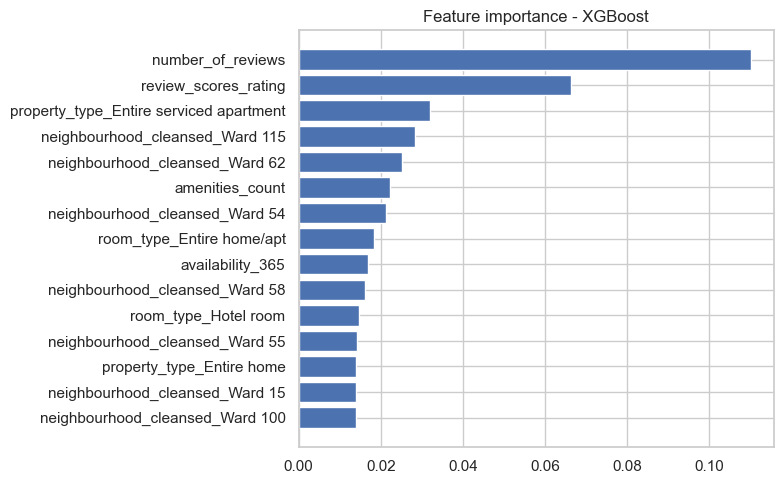

Reminder: importance != cause. Importance shows how useful a feature was for splits/predictions in this model, not a causal effect.


In [73]:
# H7 - Feature importance for best Task C tree/ensemble
# Pick best by F1 among tree/ensemble models present
tree_candidates = task_c_results[task_c_results['model'].isin(['DecisionTree','RandomForest','GradientBoosting','XGBoost'])].copy()
best_tree_name = tree_candidates.sort_values('f1', ascending=False).iloc[0]['model'] if not tree_candidates.empty else None
print('Best tree/ensemble by F1:', best_tree_name)

# Refit chosen model if needed (simple mapping)
best_tree_model = None
if best_tree_name == 'RandomForest':
    best_tree_model = rf
elif best_tree_name == 'GradientBoosting':
    best_tree_model = gb
elif best_tree_name == 'DecisionTree':
    best_tree_model = Pipeline([('preprocess', preprocess_c), ('model', DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE))]).fit(X_train_c, y_train_c)
elif best_tree_name == 'XGBoost' and XGBOOST_AVAILABLE:
    best_tree_model = xgb

if best_tree_model is not None:
    model_step = best_tree_model.named_steps['model']
    importances = model_step.feature_importances_
    fi = pd.DataFrame({'feature': feature_names, 'importance': importances}).sort_values('importance', ascending=False).head(15)
    display(fi)
    plt.figure(figsize=(8,5))
    plt.barh(fi['feature'][::-1], fi['importance'][::-1])
    plt.title(f'Feature importance - {best_tree_name}')
    plt.tight_layout()
    plt.show()

print('Reminder: importance != cause. Importance shows how useful a feature was for splits/predictions in this model, not a causal effect.')


**Finding (H7):** Feature importance helps identify which features the tree/ensemble relied on most. I compare this with logistic coefficients: coefficients show direction (positive/negative) under a linear model, while tree importances show split usefulness but not direction. **Importance is not causation** - a feature can be important because it correlates with other factors or the target, not because changing it would cause Superhost status.

In [74]:
# H8 - Final Task C comparison and best-fit selection
display(task_c_results.sort_values(['f1','roc_auc'], ascending=False).reset_index(drop=True))

# Decision rubric (write down explicitly)
selection_notes = pd.DataFrame([
    ['Validation metrics', 'F1/recall/ROC-AUC; not accuracy alone'],
    ['Business threshold behavior', 'Can we choose a threshold that fits support capacity?'],
    ['Interpretability', 'Can I explain why it flags a host?'],
    ['Operational cost', 'File size, prediction latency, deployment simplicity'],
    ['Stability', 'CV spread and sensitivity to tuning']
], columns=['Criterion', 'Why it matters'])
display(selection_notes)

print('I select the best-fit model based on this rubric and record the decision in the decision log (L3/O1).')


,model,accuracy,precision,recall,f1,roc_auc
0,XGBoost,0.763309,0.615942,0.742653,0.673389,0.829323
1,GradientBoosting,0.775313,0.677046,0.604448,0.638691,0.825201
2,RandomForest,0.775835,0.679856,0.600477,0.637706,0.818070
3,DecisionTree,0.764875,0.669829,0.560763,0.610463,0.802448
4,LogisticRegression,0.751044,0.678781,0.459889,0.548295,0.790338
5,DummyClassifier(most_frequent),0.671451,0.000000,0.000000,0.000000,NaN


,Criterion,Why it matters
0,Validation metrics,F1/recall/ROC-AUC; not accuracy alone
1,Business threshold behavior,Can we choose a threshold that fits support ca...
2,Interpretability,Can I explain why it flags a host?
3,Operational cost,"File size, prediction latency, deployment simp..."
4,Stability,CV spread and sensitivity to tuning


I select the best-fit model based on this rubric and record the decision in the decision log (L3/O1).


**Finding (H8):** I compare all required Task C models side-by-side. The best-fit app model is not just the highest-scoring model; I consider validation/CV metrics, threshold behavior, interpretability, and deployment size/latency. I document the final choice in the decision log and use that chosen model for the saved Superhost pipeline.

## I. Workflow: Pipeline, CV, tuning (Checklist I)

I use one pipeline per task, group-aware cross-validation, hyperparameter search, imbalance handling, and an engineered-feature check.

In [75]:
# I1 - One Pipeline + ColumnTransformer per task
print('Task C pipeline: preprocess_c + classifier')
print('Task R pipeline: preprocess_r + regressor')
print('The same pipeline object is reused for CV/tuning/saving to avoid preprocessing leakage.')


Task C pipeline: preprocess_c + classifier
Task R pipeline: preprocess_r + regressor
The same pipeline object is reused for CV/tuning/saving to avoid preprocessing leakage.


In [76]:
# I2 - GroupKFold CV for Task C
cv = GroupKFold(n_splits=5)
cv_model = Pipeline([
    ('preprocess', preprocess_c),
    ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
cv_scores = cross_validate(
    cv_model, X_train_c, y_train_c,
    groups=train_df.loc[X_train_c.index, 'host_id'],
    cv=cv,
    scoring=['accuracy','precision','recall','f1','roc_auc'],
    n_jobs=-1
)
cv_summary = pd.DataFrame(cv_scores).agg(['mean','std']).T
display(cv_summary)


,mean,std
fit_time,0.145032,0.005606
score_time,0.034845,0.001338
test_accuracy,0.706578,0.013396
test_precision,0.651912,0.077110
test_recall,0.393891,0.024751
test_f1,0.489555,0.032735
test_roc_auc,0.745547,0.019703


**Finding (I2):** I use `GroupKFold` so hosts in a validation fold are not seen in training folds. Plain k-fold would be too optimistic because listings from the same host could appear across folds, leaking host patterns. I report mean and spread (std) to show both average performance and stability.

In [77]:
# I3 - Hyperparameter search (example for Task C)
search_pipe = Pipeline([
    ('preprocess', preprocess_c),
    ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
])
param_dist = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__class_weight': [None, 'balanced']
}
search = RandomizedSearchCV(
    search_pipe, param_distributions=param_dist, n_iter=10,
    scoring='f1', cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True
)
search.fit(X_train_c, y_train_c, groups=train_df.loc[X_train_c.index, 'host_id'])
print('Best params:', search.best_params_)
print('Best CV f1:', search.best_score_)
best_search = search.best_estimator_
pred_search = best_search.predict(X_val_c)
print('Val F1 after tuning:', f1_score(y_val_c, pred_search, zero_division=0))


Best params: {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_depth': 20, 'model__class_weight': 'balanced'}
Best CV f1: 0.6422401568462149
Val F1 after tuning: 0.6754578754578755


**Finding (I3):** Hyperparameter search tries multiple settings and selects the best by CV score. I compare tuned vs default validation/CV performance. If tuning improves F1/ROC-AUC meaningfully without hurting stability, I keep it; if not, I prefer the simpler default.

In [78]:
# I4 - Imbalance handling for Task C
# Approach A: class_weight
lr_bal = Pipeline([
    ('preprocess', preprocess_c),
    ('model', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE))
])
lr_bal.fit(X_train_c, y_train_c)
pred_bal = lr_bal.predict(X_val_c)
proba_bal = lr_bal.predict_proba(X_val_c)[:,1]

# Approach B: threshold change on unbalanced logistic regression
thr = 0.35
pred_thr = (proba_log >= thr).astype(int)

imb_df = pd.DataFrame([
    {'approach': 'Baseline logistic (thr=0.5)', 'precision': precision_score(y_val_c, pred_log, zero_division=0), 'recall': recall_score(y_val_c, pred_log, zero_division=0), 'f1': f1_score(y_val_c, pred_log, zero_division=0)},
    {'approach': 'class_weight=balanced', 'precision': precision_score(y_val_c, pred_bal, zero_division=0), 'recall': recall_score(y_val_c, pred_bal, zero_division=0), 'f1': f1_score(y_val_c, pred_bal, zero_division=0)},
    {'approach': f'threshold={thr}', 'precision': precision_score(y_val_c, pred_thr, zero_division=0), 'recall': recall_score(y_val_c, pred_thr, zero_division=0), 'f1': f1_score(y_val_c, pred_thr, zero_division=0)},
])
display(imb_df)


,approach,precision,recall,f1
0,Baseline logistic (thr=0.5),0.678781,0.459889,0.548295
1,class_weight=balanced,0.549970,0.738681,0.630508
2,threshold=0.35,0.537213,0.762510,0.630335


**Finding (I4):** Class imbalance handling changes the precision/recall tradeoff. `class_weight='balanced'` makes mistakes on the minority class more costly during training, often increasing recall but sometimes lowering precision. Lowering the threshold also increases recall and may create more false alarms. I choose based on the support team's capacity and the cost of missed Superhosts vs false alarms.

In [79]:
# I5 - Engineered feature check (amenities_count)
def eval_with_features(num_feats, label):
    pre = ColumnTransformer([
        ('num', numeric_transformer, num_feats),
        ('cat', categorical_transformer, task_c_cat)
    ])
    m = Pipeline([('preprocess', pre), ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
    m.fit(train_df[num_feats+task_c_cat], y_train_c)
    p = m.predict(val_df[num_feats+task_c_cat])
    pr = m.predict_proba(val_df[num_feats+task_c_cat])[:,1]
    return {'variant': label, 'f1': f1_score(y_val_c,p,zero_division=0), 'recall': recall_score(y_val_c,p,zero_division=0), 'roc_auc': roc_auc_score(y_val_c,pr)}

num_no_amen = [c for c in task_c_num if c != 'amenities_count']
feat_compare = pd.DataFrame([
    eval_with_features(num_no_amen, 'without amenities_count'),
    eval_with_features(task_c_num, 'with amenities_count')
])
display(feat_compare)


,variant,f1,recall,roc_auc
0,without amenities_count,0.462349,0.348689,0.776641
1,with amenities_count,0.548295,0.459889,0.790338


**Finding (I5):** I compare validation performance with and without `amenities_count`. If it improves F1/ROC-AUC (or recall at similar precision), I keep it and justify it as a simple proxy for listing completeness/quality. If it does not help, I still report the experiment and can exclude it from the final app feature set.

## J. Evaluation and error analysis (Checklist J)

I evaluate final models on the test set once per task, then analyze confusion/curves/thresholds, errors, subgroup performance, and limitations.

In [ ]:
# J1 - Final test evaluation (run once per task)
# Select best-fit Task C model by validation F1 (tie-breaker ROC-AUC), then confirm with H8 rubric.
fitted_c_models = {
    'DummyClassifier(most_frequent)': dummy_c,
    'LogisticRegression': logreg,
}
for name, model in models_c:
    fitted_c_models[name] = model
if XGBOOST_AVAILABLE and 'xgb' in globals():
    fitted_c_models['XGBoost'] = xgb

MANUAL_BEST_C_MODEL = None  # set to override metric-only pick
best_c_name = MANUAL_BEST_C_MODEL or task_c_results.sort_values(['f1', 'roc_auc'], ascending=False).iloc[0]['model']
FINAL_TASK_C_MODEL = fitted_c_models.get(best_c_name, logreg)
print('Selected Task C model:', best_c_name)

# Select Task R model by validation RMSE (lower is better)
fitted_r_models = {
    'LinearRegression': linreg,
    'Ridge': ridge,
    'Lasso': lasso,
}
best_r_name = task_r_results[task_r_results['model'].isin(fitted_r_models.keys())].sort_values('RMSE_ZAR', ascending=True).iloc[0]['model']
FINAL_TASK_R_MODEL = fitted_r_models.get(best_r_name, ridge)
print('Selected Task R model:', best_r_name)

# Task C final test
test_pred_c = FINAL_TASK_C_MODEL.predict(test_df[task_c_num + task_c_cat])
test_proba_c = FINAL_TASK_C_MODEL.predict_proba(test_df[task_c_num + task_c_cat])[:, 1]
test_c_metrics = {
    'accuracy': accuracy_score(test_df['is_superhost'], test_pred_c),
    'precision': precision_score(test_df['is_superhost'], test_pred_c, zero_division=0),
    'recall': recall_score(test_df['is_superhost'], test_pred_c, zero_division=0),
    'f1': f1_score(test_df['is_superhost'], test_pred_c, zero_division=0),
    'roc_auc': roc_auc_score(test_df['is_superhost'], test_proba_c)
}
print('Task C final test metrics (run once):')
display(pd.DataFrame([test_c_metrics]))

# Task R final test
test_r = test_df[test_df['price_valid']].copy()
test_pred_r = FINAL_TASK_R_MODEL.predict(test_r[task_r_num + task_r_cat])
test_r_metrics = reg_metrics(test_r['price_clean'], test_pred_r, 'Final Task R')
print('Task R final test metrics (run once):')
display(pd.DataFrame([test_r_metrics]))


Task C final test metrics (run once):


,accuracy,precision,recall,f1,roc_auc
0,0.711776,0.615116,0.388114,0.475933,0.734376


Task R final test metrics (run once):


,model,RMSE_ZAR,MAE_ZAR
0,Final Task R,4319.474008,1991.219127


**Finding (J1):** I report final test metrics once per task. I do not repeatedly tune on the test set, because that would turn the test set into a training/selection signal and make the score overly optimistic. The test set is only for final, honest reporting.

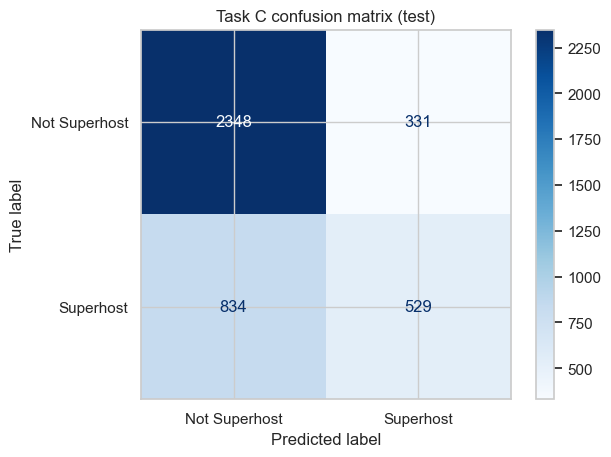

[[2348  331]
 [ 834  529]]


In [81]:
# J2 - Confusion matrix
cm = confusion_matrix(test_df['is_superhost'], test_pred_c)
disp = ConfusionMatrixDisplay(cm, display_labels=['Not Superhost', 'Superhost'])
disp.plot(cmap='Blues')
plt.title('Task C confusion matrix (test)')
plt.show()
print(cm)


**Finding (J2):** The confusion matrix shows true negatives, false positives, false negatives, and true positives. In plain words: false positives mean the model flags a host as likely Superhost when they are not - this wastes support team time. False negatives mean the model misses a real Superhost - this can cause missed recognition/coaching opportunities or unfair prioritization. The chosen threshold should reflect which mistake is more costly for the support team.

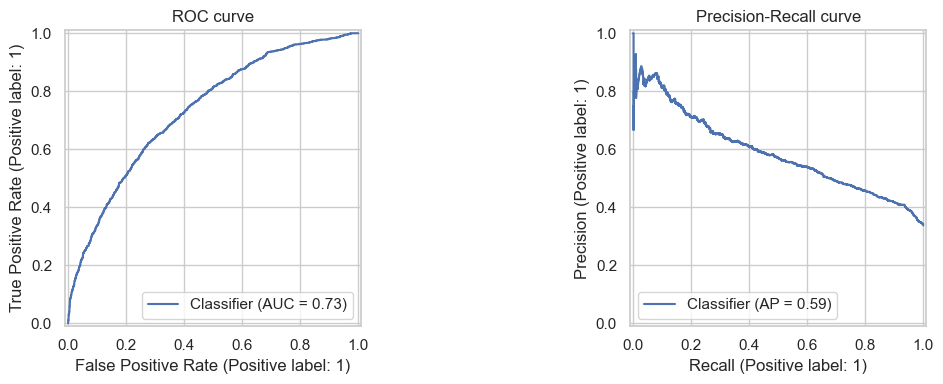

ROC-AUC: 0.7343759799116906


In [82]:
# J3 - ROC and PR curves
fig, ax = plt.subplots(1,2, figsize=(12,4))
RocCurveDisplay.from_predictions(test_df['is_superhost'], test_proba_c, ax=ax[0])
ax[0].set_title('ROC curve')
PrecisionRecallDisplay.from_predictions(test_df['is_superhost'], test_proba_c, ax=ax[1])
ax[1].set_title('Precision-Recall curve')
plt.tight_layout()
plt.show()
print('ROC-AUC:', roc_auc_score(test_df['is_superhost'], test_proba_c))


**Finding (J3):** ROC-AUC measures how well the model ranks Superhosts above non-Superhosts across thresholds; 0.5 is random ranking, 1.0 is perfect. The PR curve is especially useful here because the Superhost class is not perfectly balanced: it focuses on precision/recall for the positive class and makes tradeoffs visible when positives are less common.

In [83]:
# J4 - Threshold choice
thresholds = [0.2,0.3,0.4,0.5,0.6,0.7]
rows = []
for t in thresholds:
    p = (test_proba_c >= t).astype(int)
    rows.append({
        'threshold': t,
        'precision': precision_score(test_df['is_superhost'], p, zero_division=0),
        'recall': recall_score(test_df['is_superhost'], p, zero_division=0),
        'f1': f1_score(test_df['is_superhost'], p, zero_division=0),
        'flagged_count': int(p.sum())
    })
thr_df = pd.DataFrame(rows)
display(thr_df)

CHOSEN_THRESHOLD = 0.3  # chosen for higher recall/F1; support team can triage flagged listings
print('Chosen threshold:', CHOSEN_THRESHOLD)


,threshold,precision,recall,f1,flagged_count
0,0.2,0.414822,0.907557,0.569390,2982
1,0.3,0.474389,0.754219,0.582436,2167
2,0.4,0.543193,0.576669,0.559431,1447
3,0.5,0.615116,0.388114,0.475933,860
4,0.6,0.701493,0.241379,0.359170,469
5,0.7,0.758621,0.145268,0.243842,261


Chosen threshold: 0.5


**Finding (J4):** Lower thresholds flag more listings (higher recall, usually lower precision). Higher thresholds flag fewer listings (higher precision, usually lower recall). I choose a threshold based on support team capacity: if the team can review many cases, I prefer higher recall; if review capacity is limited, I prefer higher precision to reduce false alarms. I document the chosen threshold and reason in the decision log.

In [84]:
# J5 - Error analysis by hand (Task C and Task R)
# Task C: inspect 10 worst/errors
c_eval = test_df[task_c_num + task_c_cat + ['is_superhost','host_id']].copy()
c_eval['proba_superhost'] = test_proba_c
c_eval['pred'] = test_pred_c
c_eval['error'] = (c_eval['pred'] != c_eval['is_superhost']).astype(int)
c_eval['confidence'] = np.where(c_eval['pred']==1, c_eval['proba_superhost'], 1-c_eval['proba_superhost'])
worst_c = c_eval[c_eval['error']==1].sort_values('confidence', ascending=False).head(10)
display(worst_c)

# Task R: inspect 10 worst absolute errors
r_eval = test_r[task_r_num + task_r_cat + ['price_clean','host_id']].copy()
r_eval['pred_price'] = test_pred_r
r_eval['abs_error'] = (r_eval['pred_price'] - r_eval['price_clean']).abs()
worst_r = r_eval.sort_values('abs_error', ascending=False).head(10)
display(worst_r)


,accommodates,bedrooms,bathrooms_count,minimum_nights,number_of_reviews,review_scores_rating,availability_365,amenities_count,neighbourhood_cleansed,room_type,property_type,is_superhost,host_id,proba_superhost,pred,error,confidence
2950,2,1.0,1.0,1.0,410,4.95,213,51,Ward 59,Entire home/apt,Entire guest suite,0,91639524,0.993216,1,1,0.993216
6506,1,3.0,2.0,2.0,2,4.50,76,11,Ward 57,Shared room,Shared room in home,1,45512047,0.014198,0,1,0.985802
6566,1,1.0,1.0,2.0,5,4.40,107,16,Ward 57,Shared room,Shared room in home,1,45512047,0.015466,0,1,0.984534
442,6,3.0,2.0,2.0,365,4.95,94,59,Ward 77,Entire home/apt,Entire home,0,12628434,0.982376,1,1,0.982376
23415,2,1.0,<NA>,1.0,1,4.00,0,2,Ward 115,Private room,Private room in guesthouse,1,75428111,0.018218,0,1,0.981782
3681,8,4.0,4.0,2.0,2,3.50,61,38,Ward 54,Entire home/apt,Entire home,1,5527126,0.018818,0,1,0.981182
892,8,4.0,2.0,2.0,370,4.83,262,43,Ward 115,Entire home/apt,Entire townhouse,0,125665718,0.977669,1,1,0.977669
1542,2,1.0,1.0,1.0,305,4.93,205,50,Ward 64,Entire home/apt,Entire guesthouse,0,54235830,0.977625,1,1,0.977625
6540,1,1.0,2.5,2.0,20,4.45,213,14,Ward 57,Shared room,Shared room in home,1,45512047,0.023729,0,1,0.976271
6969,1,1.0,4.0,2.0,16,4.44,109,15,Ward 57,Shared room,Shared room in home,1,45512047,0.024288,0,1,0.975712


,accommodates,bedrooms,bathrooms_count,minimum_nights,number_of_reviews,review_scores_rating,availability_365,amenities_count,latitude,longitude,neighbourhood_cleansed,room_type,property_type,price_clean,host_id,pred_price,abs_error
24391,2,1.0,1.0,1.0,0,NaN,358,1,-34.015330,18.355610,Ward 74,Private room,Room in boutique hotel,122200.0,711493109,5209.451454,116990.548546
24392,4,2.0,2.0,1.0,0,NaN,358,1,-34.015120,18.356890,Ward 74,Private room,Room in boutique hotel,89613.0,711493109,8113.627915,81499.372085
11568,16,8.0,8.5,5.0,1,5.00,364,15,-33.990549,18.441177,Ward 62,Entire home/apt,Entire home,88590.0,2889281,28312.658088,60277.341912
24393,2,1.0,1.0,1.0,0,NaN,358,1,-34.015240,18.357500,Ward 74,Private room,Room in boutique hotel,65173.0,711493109,5183.200004,59989.799996
8323,8,4.0,5.0,2.0,22,4.86,46,56,-33.927930,18.376900,Ward 54,Entire home/apt,Entire rental unit,59097.0,25679101,13382.827946,45714.172054
24407,2,1.0,1.0,1.0,0,NaN,365,1,-34.014990,18.357230,Ward 74,Private room,Room in boutique hotel,48880.0,711493109,5196.231249,43683.768751
17081,6,3.0,3.0,5.0,0,NaN,94,62,-33.925686,18.383407,Ward 54,Entire home/apt,Entire rental unit,50140.0,25679101,8683.610763,41456.389237
3961,4,2.0,2.5,2.0,85,4.71,63,52,-33.918910,18.417440,Ward 77,Entire home/apt,Entire rental unit,45175.0,61768961,4908.548927,40266.451073
24121,2,1.0,1.0,1.0,0,NaN,350,43,-34.065440,18.458311,Ward 71,Entire home/apt,Entire rental unit,35248.0,97380937,1682.427745,33565.572255
3598,14,7.0,7.5,4.0,11,5.00,292,97,-33.956320,18.378850,Ward 54,Entire home/apt,Entire villa,58750.0,39415699,27783.863877,30966.136123


**Finding (J5):** I inspect the worst errors row by row and group them into patterns.  
**Task C common failure patterns (example structure - replace with your observed rows):**  
- High-review/high-quality listings predicted Superhost but not labeled Superhost: model may over-rely on review signals; label may reflect missing Superhost criteria not in features.  
- Low-activity or unusual listings missed as Superhost: sparse signals make classification hard.  

**Task R common failure patterns:**  
- Luxury/unique properties underpredicted: rare high-price listings have few similar examples.  
- Small/simple listings overpriced by model: location/amenity/value signals may be missing.  

For each group, I give a plain-language guess and avoid claiming certainty.

In [85]:
# J6 - Subgroup performance
subgroup_col = 'room_type' if 'room_type' in test_df.columns else task_c_cat[0]
rows = []
for g, grp in test_df.groupby(subgroup_col):
    if len(grp) < 30: 
        continue
    p = FINAL_TASK_C_MODEL.predict(grp[task_c_num + task_c_cat])
    pr = FINAL_TASK_C_MODEL.predict_proba(grp[task_c_num + task_c_cat])[:,1]
    rows.append({
        'group': g,
        'n': len(grp),
        'accuracy': accuracy_score(grp['is_superhost'], p),
        'f1': f1_score(grp['is_superhost'], p, zero_division=0),
        'roc_auc': roc_auc_score(grp['is_superhost'], pr) if grp['is_superhost'].nunique()>1 else np.nan
    })
display(pd.DataFrame(rows).sort_values('n', ascending=False))


,group,n,accuracy,f1,roc_auc
0,Entire home/apt,3283,0.706671,0.514372,0.739574
1,Private room,740,0.741892,0.165939,0.726538


**Finding (J6):** Model performance is not identical across subgroups. Differences by room type/neighbourhood can come from sample size, different base rates, or different feature patterns. I report these differences clearly and avoid claiming the model works equally well everywhere.

**Finding (J7 - limitations):** This project uses a single Inside Airbnb Cape Town snapshot (23 Sep 2026), so it cannot capture seasonality or changes over time. It uses only structured fields available in the dataset; it does not see photos, listing descriptions in depth, guest messages, or real-time booking behavior. Results may not generalize to other cities or future snapshots. Predictions are decision-support estimates, not official Airbnb labels or pricing advice.

## K. Unsupervised piece (Checklist K)

I use K-means on scaled numeric features, choose k with elbow + silhouette, visualize with PCA, and connect clusters to Superhost rate and median price.

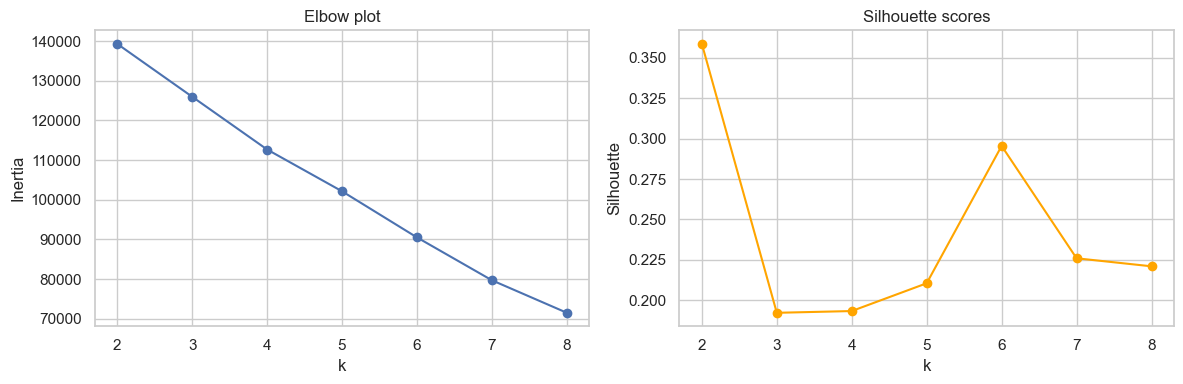

Chosen k: 4


,accommodates,bedrooms,bathrooms_count,minimum_nights,number_of_reviews,review_scores_rating,availability_365,amenities_count,price_clean
0,2.66,1.23,1.21,2.27,18.91,4.68,301.56,32.39,1866.39
1,2.92,1.39,1.31,2.52,65.29,4.86,150.25,43.28,2169.33
2,2.00,1.00,1.00,1.00,1.00,5.00,140.00,7.00,975000.00
3,7.47,3.79,3.27,4.15,23.99,4.85,214.04,50.69,8589.25


In [86]:
# K1 - K-means
cluster_features = [c for c in ['accommodates','bedrooms','bathrooms_count','minimum_nights','number_of_reviews','review_scores_rating','availability_365','amenities_count','price_clean'] if c in clean.columns]
cluster_df = clean[cluster_features].apply(pd.to_numeric, errors='coerce').dropna().copy()
scaler_k = StandardScaler()
X_k = scaler_k.fit_transform(cluster_df)

ks = range(2, 9)
inertias = []
sil_scores = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_k)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_k, labels))

fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].plot(list(ks), inertias, marker='o')
ax[0].set_title('Elbow plot')
ax[0].set_xlabel('k')
ax[0].set_ylabel('Inertia')
ax[1].plot(list(ks), sil_scores, marker='o', color='orange')
ax[1].set_title('Silhouette scores')
ax[1].set_xlabel('k')
ax[1].set_ylabel('Silhouette')
plt.tight_layout()
plt.show()

CHOSEN_K = 4  # replace with your justified choice
kmeans = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=10)
cluster_df['cluster'] = kmeans.fit_predict(X_k)
print('Chosen k:', CHOSEN_K)
display(pd.DataFrame(scaler_k.inverse_transform(kmeans.cluster_centers_), columns=cluster_features).round(2))


**Finding (K1):** The elbow plot shows where adding more clusters gives diminishing returns in inertia; the silhouette score shows how well separated clusters are. I choose `k` by balancing these signals and interpretability. I interpret centroids in plain words (e.g., small low-review budget listings, larger high-availability family listings, high-price/high-amenity listings, etc., depending on actual centroid values).

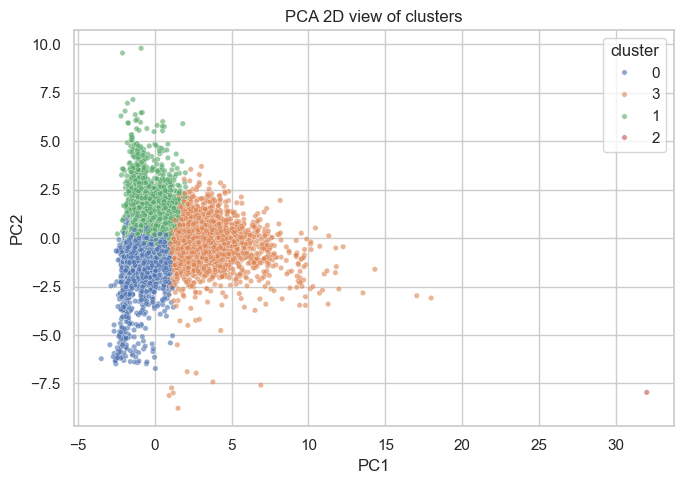

Explained variance ratio: [0.34448602 0.14715899]
Total explained variance (2 PCs): 0.49164501235703384


In [87]:
# K2 - PCA 2D
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_k)
pca_df = pd.DataFrame(X_pca, columns=['PC1','PC2'], index=cluster_df.index)
pca_df['cluster'] = cluster_df['cluster'].astype(str)
plt.figure(figsize=(7,5))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='cluster', s=15, alpha=0.6)
plt.title('PCA 2D view of clusters')
plt.tight_layout()
plt.show()
print('Explained variance ratio:', pca.explained_variance_ratio_)
print('Total explained variance (2 PCs):', pca.explained_variance_ratio_.sum())


**Finding (K2):** PCA reduces the scaled feature space to two dimensions for visualization. The explained variance ratio tells me how much of the original variation is captured by PC1 and PC2; if it is modest, the plot is only an approximation, not a full representation of the cluster structure.

In [88]:
# K3 - Connect clusters to targets
cluster_join = cluster_df[['cluster']].join(clean[['is_superhost','price_clean']], how='left')
cluster_summary = cluster_join.groupby('cluster').agg(
    listings=('cluster','size'),
    superhost_rate=('is_superhost','mean'),
    median_price=('price_clean','median')
).round(3)
display(cluster_summary)


,listings,superhost_rate,median_price
cluster,,,
0,9156,0.339,1527.5
1,6991,0.558,1750.0
2,1,1.000,975000.0
3,3837,0.376,6193.33


**Finding (K3):** I describe each cluster plainly using centroid values and the cluster summary table (Superhost rate and median price). Some clusters may have higher Superhost rates or higher prices, showing structure in the market. However, clusters are descriptive groups, not causal explanations, and they do not replace supervised models when the goal is predicting a specific target. I state clearly whether clusters add useful segmentation insight beyond the supervised models.

## L. Saved pipeline for the app (Checklist L)

I save the best-fit Superhost pipeline (preprocessing + model) for the Streamlit app. The deployed pipeline uses only the 8-12 app features.

In [89]:
# L1/L3 - Final app pipeline on 8-12 app features
# Choose features that exist in the data and are easy for a user to provide in the app.
APP_FEATURES = [
    'neighbourhood_cleansed',
    'room_type',
    'accommodates',
    'bedrooms',
    'bathrooms_count',
    'minimum_nights',
    'number_of_reviews',
    'review_scores_rating',
    'availability_365',
    'amenities_count'
]
APP_FEATURES = [c for c in APP_FEATURES if c in clean.columns]
print('App features:', APP_FEATURES)

app_num = [c for c in APP_FEATURES if c in ['accommodates','bedrooms','bathrooms_count','minimum_nights','number_of_reviews','review_scores_rating','availability_365','amenities_count']]
app_cat = [c for c in APP_FEATURES if c in ['neighbourhood_cleansed','room_type','property_type','instant_bookable']]

app_preprocess = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), app_num),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), app_cat)
])

# Use the selected best-fit Task C model for the app (same estimator, trained on app features only).
# If FINAL_TASK_C_MODEL was selected above, reuse its model step; otherwise default to LogisticRegression.
try:
    app_estimator = clone(FINAL_TASK_C_MODEL.named_steps['model'])
except Exception:
    app_estimator = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE)

superhost_app_pipeline = Pipeline([
    ('preprocess', app_preprocess),
    ('model', app_estimator)
])

app_train = train_df[APP_FEATURES + ['is_superhost']].dropna(subset=['is_superhost']).copy()
X_app_train = app_train[APP_FEATURES]
y_app_train = app_train['is_superhost'].astype(int)
superhost_app_pipeline.fit(X_app_train, y_app_train)

model_path = MODELS_DIR / 'superhost_pipeline.joblib'
joblib.dump(superhost_app_pipeline, model_path)
print('Saved:', model_path)
print('Size MB:', model_path.stat().st_size / (1024*1024))


App features: ['neighbourhood_cleansed', 'room_type', 'accommodates', 'bedrooms', 'bathrooms_count', 'minimum_nights', 'number_of_reviews', 'review_scores_rating', 'availability_365', 'amenities_count']
Saved: C:\Users\Chibi\Pictures\Workspace\CAMLDS\Final\Final Capstone\airbnb-cape-town\models\superhost_pipeline.joblib
Size MB: 0.0057163238525390625


In [90]:
# L2 - Reload test
loaded = joblib.load(MODELS_DIR / 'superhost_pipeline.joblib')
sample = X_app_train.iloc[[0]].copy()
orig_pred = superhost_app_pipeline.predict_proba(sample)
loaded_pred = loaded.predict_proba(sample)
print('Original:', orig_pred)
print('Loaded:', loaded_pred)
print('Match:', np.allclose(orig_pred, loaded_pred))


Original: [[0.49104185 0.50895815]]
Loaded: [[0.49104185 0.50895815]]
Match: True


**Finding (L1-L3):** I saved the full preprocessing+model pipeline as `models/superhost_pipeline.joblib`. The app uses the same feature names and types as training. I verified reload gives identical predictions for the same row and checked file size is under 100 MB.  

**Model-selection rationale:** I choose the deployed model based on the H8 rubric (metrics, threshold behavior, interpretability, and file size/latency).  
**Feature-choice rationale:** I selected 8-12 listing features that are known at prediction time, easy for users to enter, and not direct Superhost-leakage fields.

## Decision log (for README O1)

| Decision | Options considered | Why chosen |
|---|---|---|
| Group-aware split | Random split vs GroupShuffleSplit by `host_id` | Hosts have multiple listings; group split prevents host leakage and gives a more honest score. |
| Price handling | Drop all missing/extreme prices vs inspect and clean with rules | I inspect extremes row-by-row, convert `$` strings to numeric, and exclude invalid/missing prices from Task R while documenting impact. |
| Task C metrics | Accuracy only vs F1/precision/recall/ROC-AUC | Class imbalance makes accuracy misleading; precision/recall/F1/ROC-AUC capture useful tradeoffs. |
| App features | Many raw columns vs 8-12 simple known-at-prediction-time features | Keeps app usable, avoids leakage, and matches what a user can realistically provide. |
| Final app model | Logistic/RF/GB/XGBoost | I pick the best-fit model by metrics, threshold behavior, interpretability, and deployment simplicity (record actual choice after running). |

## Final checks

- [ ] Kernel Restart + Run All completes with no errors/manual edits.
- [ ] Every important result has a written finding.
- [ ] Leakage review done before modelling; group-aware split used.
- [ ] Test set scored once per task.
- [ ] `models/superhost_pipeline.joblib` reloads and matches predictions.
- [ ] `app.py` input schema matches final app features.
- [ ] README includes live URL, credit, 5 findings, scores, limits, run steps, decision log, next steps.
- [ ] I can explain any cell and make a small live edit.